<a href="https://colab.research.google.com/github/srimathi23-lgtm/datascience-lab/blob/main/ds_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#18-11-2026
# Exp 1
import csv
import json
import os
import pandas as pd

# Create data folder
os.makedirs("data", exist_ok=True)


# ---------- Step 1: Data Collection from Three Different Sources ----------

# Source 1: CSV file from the in-store billing (POS) system
pos_rows = [
    ["order_id", "customer", "product", "qty", "unit_price", "branch"],
    [101, "Anitha", "Laptop", 1, 54000, "Chennai"],
    [102, "Rahul", "Mouse", 3, 450, "Chennai"],
    [103, "Priya", "Keyboard", 2, 1200, "Chennai"],
    [104, "Karthik", "Monitor", 1, 9500, "Chennai"],
]

with open("data/pos_orders.csv", "w", newline="") as f:
    csv.writer(f).writerows(pos_rows)


# Source 2: JSON response from the online store (Web API)
web_orders = [
    {
        "order_id": 201,
        "customer": "Divya",
        "product": "Laptop",
        "qty": 2,
        "unit_price": 52500,
        "branch": "Online",
    },
    {
        "order_id": 202,
        "customer": "Arjun",
        "product": "Headset",
        "qty": 1,
        "unit_price": 2300,
        "branch": "Online",
    },
    {
        "order_id": 203,
        "customer": "Meena",
        "product": "Mouse",
        "qty": 5,
        "unit_price": 430,
        "branch": "Online",
    },
]

with open("data/web_orders.json", "w") as f:
    json.dump(web_orders, f, indent=2)


# Source 3: Plain-text log from the mobile app (Pipe Separated)
log_lines = [
    "301|Suresh|Monitor|2|9300|Mobile",
    "302|Lakshmi|Keyboard|1|1150|Mobile",
    "303|Vignesh|Laptop|1|55000|Mobile",
]

with open("data/mobile_orders.txt", "w") as f:
    f.write("\n".join(log_lines))


print("Retail Order Data: Collection, Storage and Retrieval")
print("=" * 55)


# ---------- Step 2: Reading Data from Each File ----------

# Read CSV data
df_pos = pd.read_csv("data/pos_orders.csv")

print("\n[1] CSV Source -> Rows:", len(df_pos))
print(df_pos.to_string(index=False))


# Read JSON data
with open("data/web_orders.json") as f:
    df_web = pd.DataFrame(json.load(f))

print("\n[2] JSON Source -> Rows:", len(df_web))
print(df_web.to_string(index=False))


# Read TXT data
cols = [
    "order_id",
    "customer",
    "product",
    "qty",
    "unit_price",
    "branch",
]

df_mob = pd.read_csv(
    "data/mobile_orders.txt",
    sep="|",
    header=None,
    names=cols
)

print("\n[3] TXT Source -> Rows:", len(df_mob))
print(df_mob.to_string(index=False))


# ---------- Step 3: Integration into a Single Dataset ----------

orders = pd.concat(
    [df_pos, df_web, df_mob],
    ignore_index=True
)

# Calculate total order amount
orders["amount"] = orders["qty"] * orders["unit_price"]

print("\n--- Integrated Dataset ---")
print(orders.to_string(index=False))

print("\nShape:", orders.shape)

print("Data Types:")
print(orders.dtypes.to_string())


# ---------- Step 4: Storage in Different Formats ----------

orders.to_csv("data/all_orders.csv", index=False)

orders.to_json(
    "data/all_orders.json",
    orient="records",
    indent=2
)

orders.to_excel(
    "data/all_orders.xlsx",
    index=False
)

print("\nFiles Stored:")

for name in [
    "all_orders.csv",
    "all_orders.json",
    "all_orders.xlsx",
]:
    file_size = os.path.getsize("data/" + name)

    print(f"  data/{name:<16} {file_size:>6} bytes")


# ---------- Step 5: Retrieval and Quick Query ----------

# Retrieve data from Excel
back = pd.read_excel("data/all_orders.xlsx")

print("\nRetrieved from Excel, Rows:", len(back))


# Calculate revenue by branch
print("\nRevenue by Branch:")

print(
    back.groupby("branch")["amount"]
    .sum()
    .sort_values(ascending=False)
    .to_string()
)


# Display orders with amount greater than 10000
print("\nOrders with Amount > 10000:")

print(
    back.loc[
        back["amount"] > 10000,
        ["order_id", "customer", "product", "amount"]
    ].to_string(index=False)
)

Retail Order Data: Collection, Storage and Retrieval

[1] CSV Source -> Rows: 4
 order_id customer  product  qty  unit_price  branch
      101   Anitha   Laptop    1       54000 Chennai
      102    Rahul    Mouse    3         450 Chennai
      103    Priya Keyboard    2        1200 Chennai
      104  Karthik  Monitor    1        9500 Chennai

[2] JSON Source -> Rows: 3
 order_id customer product  qty  unit_price branch
      201    Divya  Laptop    2       52500 Online
      202    Arjun Headset    1        2300 Online
      203    Meena   Mouse    5         430 Online

[3] TXT Source -> Rows: 3
 order_id customer  product  qty  unit_price branch
      301   Suresh  Monitor    2        9300 Mobile
      302  Lakshmi Keyboard    1        1150 Mobile
      303  Vignesh   Laptop    1       55000 Mobile

--- Integrated Dataset ---
 order_id customer  product  qty  unit_price  branch  amount
      101   Anitha   Laptop    1       54000 Chennai   54000
      102    Rahul    Mouse    3      

In [ ]:
#18-11-2026
# Exp 2
import sqlite3
import pandas as pd
import json


# ---------- Database Connection ----------

conn = sqlite3.connect(":memory:")
cur = conn.cursor()


# ---------- Step 1: Create the Relational Schema ----------

cur.executescript("""
CREATE TABLE doctors (
    doctor_id INTEGER PRIMARY KEY,
    name TEXT NOT NULL,
    department TEXT NOT NULL
);

CREATE TABLE patients (
    patient_id INTEGER PRIMARY KEY,
    name TEXT NOT NULL,
    age INTEGER,
    gender TEXT,
    city TEXT
);

CREATE TABLE visits (
    visit_id INTEGER PRIMARY KEY,
    patient_id INTEGER REFERENCES patients(patient_id),
    doctor_id INTEGER REFERENCES doctors(doctor_id),
    visit_date TEXT,
    fee REAL
);
""")


# ---------- Step 2: Insert Records ----------

# Insert doctors
cur.executemany(
    "INSERT INTO doctors VALUES (?, ?, ?)",
    [
        (1, "Dr. Ramesh", "Cardiology"),
        (2, "Dr. Kavitha", "Orthopaedics"),
        (3, "Dr. Imran", "General Medicine"),
    ],
)

# Insert patients
cur.executemany(
    "INSERT INTO patients VALUES (?, ?, ?, ?, ?)",
    [
        (1, "Ajay", 45, "M", "Chennai"),
        (2, "Bhavana", 32, "F", "Madurai"),
        (3, "Charles", 67, "M", "Chennai"),
        (4, "Deepa", 29, "F", "Coimbatore"),
        (5, "Elango", 54, "M", "Madurai"),
        (6, "Fathima", 38, "F", "Chennai"),
    ],
)

# Insert visits
cur.executemany(
    "INSERT INTO visits VALUES (?, ?, ?, ?, ?)",
    [
        (1, 1, 1, "2026-01-05", 800),
        (2, 2, 2, "2026-01-06", 600),
        (3, 3, 1, "2026-01-08", 800),
        (4, 4, 3, "2026-01-09", 300),
        (5, 5, 1, "2026-01-12", 800),
        (6, 1, 3, "2026-01-15", 300),
        (7, 6, 2, "2026-01-18", 600),
        (8, 3, 3, "2026-01-20", 300),
        (9, 2, 2, "2026-01-22", 600),
        (10, 5, 3, "2026-01-25", 300),
    ],
)

conn.commit()


# ---------- Function to Execute SQL Queries ----------

def run(title, sql):
    print(f"\n--- {title} ---")
    print("SQL:", " ".join(sql.split()))
    print(pd.read_sql_query(sql, conn).to_string(index=False))


print("Hospital Patient Records: Working with a Relational Database")
print("=" * 60)


# ---------- Q1: Patients Older Than 40 ----------

run(
    "Q1. Patients older than 40",
    """
    SELECT name, age, city
    FROM patients
    WHERE age > 40
    ORDER BY age DESC
    """,
)


# ---------- Q2: Visits with Patient and Doctor Names (JOIN) ----------

run(
    "Q2. Visits with patient and doctor names (JOIN)",
    """
    SELECT
        v.visit_id,
        p.name AS patient,
        d.name AS doctor,
        d.department,
        v.fee
    FROM visits v
    JOIN patients p ON v.patient_id = p.patient_id
    JOIN doctors d ON v.doctor_id = d.doctor_id
    ORDER BY v.visit_id
    """,
)


# ---------- Q3: Revenue and Visit Count per Department (GROUP BY) ----------

run(
    "Q3. Revenue and visit count per department (GROUP BY)",
    """
    SELECT
        d.department,
        COUNT(*) AS visits,
        SUM(v.fee) AS revenue
    FROM visits v
    JOIN doctors d ON v.doctor_id = d.doctor_id
    GROUP BY d.department
    ORDER BY revenue DESC
    """,
)


# ---------- Q4: Patients with More Than One Visit (HAVING) ----------

run(
    "Q4. Patients with more than one visit (HAVING)",
    """
    SELECT
        p.name,
        COUNT(*) AS visits
    FROM visits v
    JOIN patients p ON v.patient_id = p.patient_id
    GROUP BY p.name
    HAVING COUNT(*) > 1
    """,
)


# ---------- Step 3: Update and Delete ----------

cur.execute(
    """
    UPDATE doctors
    SET department = 'Internal Medicine'
    WHERE doctor_id = 3
    """
)

cur.execute(
    "DELETE FROM visits WHERE visit_id = 10"
)

conn.commit()

print("\nUpdated doctor 3 department; deleted visit 10.")

run(
    "Q5. Doctors table after update",
    "SELECT * FROM doctors",
)

print(
    "\nTotal visits after delete:",
    cur.execute("SELECT COUNT(*) FROM visits").fetchone()[0],
)


# ---------- Step 4: Load into Pandas for Analysis ----------

df = pd.read_sql_query(
    """
    SELECT
        p.city,
        p.gender,
        v.fee
    FROM visits v
    JOIN patients p ON v.patient_id = p.patient_id
    """,
    conn,
)

print("\n--- City-wise average fee using pandas ---")

print(
    df.groupby("city")["fee"]
    .agg(["count", "mean"])
    .round(2)
    .to_string()
)


# ---------- Step 5: Same Data as a NoSQL Document Collection ----------

rows = pd.read_sql_query(
    """
    SELECT
        p.patient_id,
        p.name,
        p.age,
        p.city,
        d.department,
        v.visit_date,
        v.fee
    FROM patients p
    JOIN visits v ON p.patient_id = v.patient_id
    JOIN doctors d ON v.doctor_id = d.doctor_id
    ORDER BY p.patient_id, v.visit_date
    """,
    conn,
)

conn.close()


# Convert relational records into NoSQL documents

collection = []

for pid, grp in rows.groupby("patient_id"):

    first = grp.iloc[0]

    collection.append(
        {
            "_id": int(pid),
            "name": first["name"],
            "age": int(first["age"]),
            "city": first["city"],
            "visits": [
                {
                    "dept": r.department,
                    "date": r.visit_date,
                    "fee": float(r.fee),
                }
                for r in grp.itertuples()
            ],
        }
    )


# Save NoSQL collection as JSON

with open("patients_nosql.json", "w") as f:
    json.dump(collection, f, indent=2)


print("\n--- NoSQL document model (one document per patient) ---")

print(json.dumps(collection[0], indent=2))


# ---------- MongoDB-like Find Function ----------

def find(coll, condition):
    """Mimics MongoDB's db.collection.find() using a Python predicate."""
    return [
        doc
        for doc in coll
        if condition(doc)
    ]


print(
    "\nMongoDB query : "
    "db.patients.find({city: 'Chennai', 'visits.dept': 'Cardiology'})"
)

result = find(
    collection,
    lambda d: d["city"] == "Chennai"
    and any(
        v["dept"] == "Cardiology"
        for v in d["visits"]
    ),
)

for doc in result:
    print(
        f"  {doc['_id']}  "
        f"{doc['name']:<8} "
        f"visits = {len(doc['visits'])}"
    )

Hospital Patient Records: Working with a Relational Database

--- Q1. Patients older than 40 ---
SQL: SELECT name, age, city FROM patients WHERE age > 40 ORDER BY age DESC
   name  age    city
Charles   67 Chennai
 Elango   54 Madurai
   Ajay   45 Chennai

--- Q2. Visits with patient and doctor names (JOIN) ---
SQL: SELECT v.visit_id, p.name AS patient, d.name AS doctor, d.department, v.fee FROM visits v JOIN patients p ON v.patient_id = p.patient_id JOIN doctors d ON v.doctor_id = d.doctor_id ORDER BY v.visit_id
 visit_id patient      doctor       department   fee
        1    Ajay  Dr. Ramesh       Cardiology 800.0
        2 Bhavana Dr. Kavitha     Orthopaedics 600.0
        3 Charles  Dr. Ramesh       Cardiology 800.0
        4   Deepa   Dr. Imran General Medicine 300.0
        5  Elango  Dr. Ramesh       Cardiology 800.0
        6    Ajay   Dr. Imran General Medicine 300.0
        7 Fathima Dr. Kavitha     Orthopaedics 600.0
        8 Charles   Dr. Imran General Medicine 300.0
    

Student Performance: Exploratory Data Analysis

First 5 records:
 roll_no gender department grade  attendance  study_hours  marks
       1 Female        CSE     C          60          4.1     79
       2   Male        ECE     D          69          7.1    100
       3 Female        ECE     A          94          3.7     85
       4   Male        ECE     C          65          1.0     60
       5 Female        ECE     B          81          2.0     56

Classification of attributes:
  roll_no      : Nominal (identifier)
  gender       : Qualitative - Nominal
  department   : Qualitative - Nominal
  grade        : Qualitative - Ordinal
  attendance   : Quantitative - Discrete
  study_hours  : Quantitative - Continuous
  marks        : Quantitative - Discrete

Summary statistics:
       attendance  study_hours   marks
count       60.00        60.00   60.00
mean        79.53         4.11   76.57
std         11.29         1.91   12.98
min         60.00         1.00   51.00
25%         70.50 

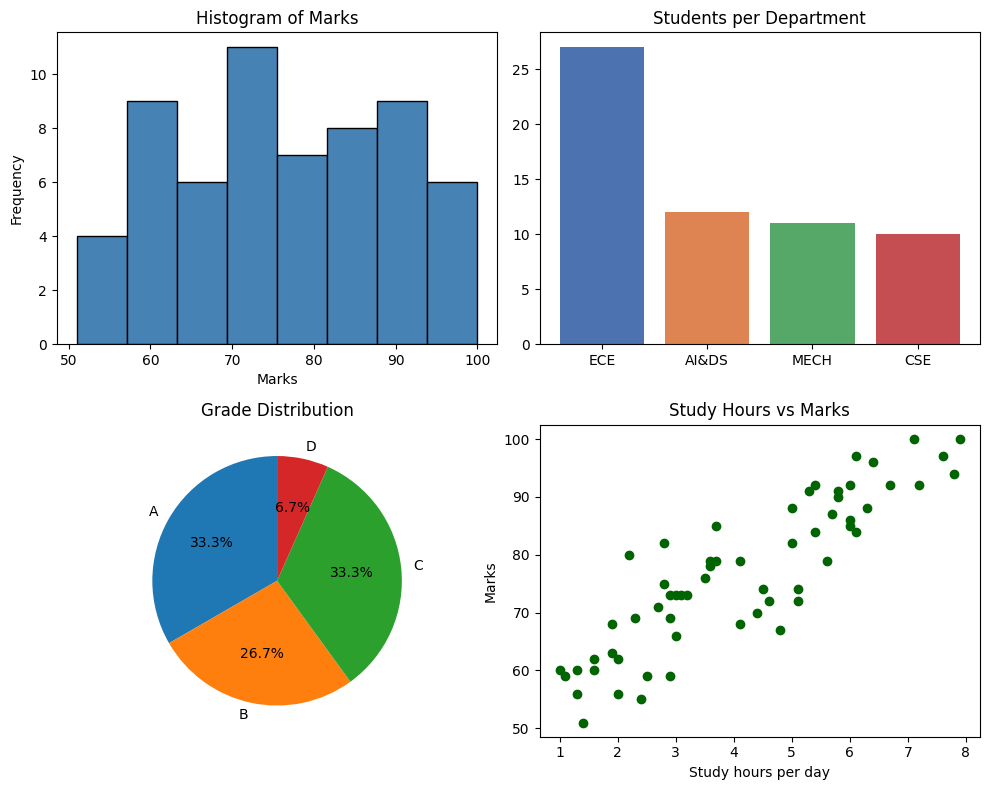


Plot saved as exp03_eda.png


In [ ]:
#19-11-2026
# Exp 3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ---------- Step 1: Generate Student Dataset ----------

np.random.seed(7)
n = 60

students = pd.DataFrame(
    {
        "roll_no": range(1, n + 1),

        "gender": np.random.choice(
            ["Male", "Female"], n
        ),

        "department": np.random.choice(
            ["CSE", "ECE", "MECH", "AI&DS"],
            n,
            p=[0.3, 0.25, 0.2, 0.25]
        ),

        "grade": np.random.choice(
            ["A", "B", "C", "D"],
            n,
            p=[0.25, 0.4, 0.25, 0.1]
        ),

        "attendance": np.random.randint(60, 100, n),

        "study_hours": np.round(
            np.random.uniform(1, 8, n), 1
        ),
    }
)

# Calculate student marks
students["marks"] = np.clip(
    (
        35
        + 6 * students["study_hours"]
        + 0.2 * students["attendance"]
        + np.random.normal(0, 6, n)
    ).round(),
    0,
    100,
).astype(int)


# ---------- Step 2: Display Student Records ----------

print("Student Performance: Exploratory Data Analysis")
print("=" * 50)

print("\nFirst 5 records:")
print(students.head().to_string(index=False))


# ---------- Step 3: Classification of Data ----------

data_types = {
    "roll_no": "Nominal (identifier)",
    "gender": "Qualitative - Nominal",
    "department": "Qualitative - Nominal",
    "grade": "Qualitative - Ordinal",
    "attendance": "Quantitative - Discrete",
    "study_hours": "Quantitative - Continuous",
    "marks": "Quantitative - Discrete",
}

print("\nClassification of attributes:")

for col, t in data_types.items():
    print(f"  {col:<12} : {t}")


# ---------- Step 4: Descriptive Statistics ----------

num = students[
    ["attendance", "study_hours", "marks"]
]

print("\nSummary statistics:")
print(num.describe().round(2).to_string())

print("\nMedian:", num.median().to_dict())

print(
    "Mode of grade:",
    students["grade"].mode()[0]
)

print(
    "Skewness of marks:",
    round(students["marks"].skew(), 3)
)


# ---------- Step 5: Frequency Table ----------

print("\nFrequency table - department:")

print(
    students["department"]
    .value_counts()
    .to_string()
)


# ---------- Step 6: Cross Table ----------

print("\nCross table - department vs grade:")

print(
    pd.crosstab(
        students["department"],
        students["grade"]
    ).to_string()
)


# ---------- Step 7: Correlation Matrix ----------

print("\nCorrelation matrix:")

print(
    num.corr()
    .round(3)
    .to_string()
)


# ---------- Step 8: Graphical Presentation ----------

fig, ax = plt.subplots(
    2, 2,
    figsize=(10, 8)
)


# Graph 1: Histogram of Marks

ax[0, 0].hist(
    students["marks"],
    bins=8,
    color="steelblue",
    edgecolor="black"
)

ax[0, 0].set_title("Histogram of Marks")
ax[0, 0].set_xlabel("Marks")
ax[0, 0].set_ylabel("Frequency")


# Graph 2: Students per Department

dept = students["department"].value_counts()

ax[0, 1].bar(
    dept.index,
    dept.values,
    color=[
        "#4c72b0",
        "#dd8452",
        "#55a868",
        "#c44e52"
    ]
)

ax[0, 1].set_title("Students per Department")


# Graph 3: Grade Distribution

grade = students["grade"].value_counts().sort_index()

ax[1, 0].pie(
    grade.values,
    labels=grade.index,
    autopct="%1.1f%%",
    startangle=90
)

ax[1, 0].set_title("Grade Distribution")


# Graph 4: Study Hours vs Marks

ax[1, 1].scatter(
    students["study_hours"],
    students["marks"],
    c="darkgreen"
)

ax[1, 1].set_title("Study Hours vs Marks")
ax[1, 1].set_xlabel("Study hours per day")
ax[1, 1].set_ylabel("Marks")


# Adjust graph layout
plt.tight_layout()


# Save and display graphs
plt.savefig(
    "exp03_eda.png",
    dpi=150
)

plt.show()

print("\nPlot saved as exp03_eda.png")

In [ ]:
#19-11-2026
# Exp 4
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# ---------- Step 1: Generate Customer Dataset ----------

np.random.seed(42)
n = 200

df = pd.DataFrame(
    {
        "customer_id": range(1001, 1001 + n),

        "age": np.random.randint(18, 70, n).astype(float),

        "income": np.random.normal(
            45000, 12000, n
        ).round(),

        "city": np.random.choice(
            ["Chennai", "chennai ", "Madurai", "Coimbatore"],
            n
        ),

        "purchases": np.random.poisson(
            6, n
        ).astype(float),

        "churn": np.random.choice(
            ["Yes", "No"],
            n,
            p=[0.3, 0.7]
        ),
    }
)


# ---------- Step 2: Inject Data Quality Problems ----------

# Missing values
df.loc[
    np.random.choice(n, 15, replace=False),
    "age"
] = np.nan

df.loc[
    np.random.choice(n, 10, replace=False),
    "income"
] = np.nan

# Outliers and invalid values
df.loc[[5, 50, 120], "income"] = [
    450000, 520000, -3000
]

# Add duplicate records
df = pd.concat(
    [df, df.iloc[[10, 20, 30, 40, 50]]],
    ignore_index=True
)


# ---------- Step 3: Display Raw Dataset ----------

print("Customer Data: Cleaning and Sampling for Modeling")
print("=" * 50)

print("Raw shape:", df.shape)


# ---------- Step 4: Handle Missing Values ----------

print("\n[1] Missing values per column:")
print(df.isnull().sum().to_string())


# ---------- Step 5: Remove Duplicate Records ----------

dups = df.duplicated().sum()

df = df.drop_duplicates()

print(
    f"\n[2] Duplicate rows removed: {dups} "
    f"-> shape {df.shape}"
)


# ---------- Step 6: Correct Inconsistent Categories ----------

print(
    "\n[3] City values before:",
    sorted(df["city"].unique())
)

df["city"] = (
    df["city"]
    .str.strip()
    .str.title()
)

print(
    "    City values after :",
    sorted(df["city"].unique())
)


# ---------- Step 7: Handle Invalid Values and Outliers ----------

df.loc[
    df["income"] < 0,
    "income"
] = np.nan

q1, q3 = df["income"].quantile([0.25, 0.75])

iqr = q3 - q1

low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

outliers = df[
    (df["income"] < low) |
    (df["income"] > high)
]

print(
    f"\n[4] Income IQR bounds: {low:.0f} to {high:.0f}"
)

print("    Outliers found:", len(outliers))

print(
    outliers[
        ["customer_id", "income"]
    ].to_string(index=False)
)

# Replace outliers using clipping
df["income"] = df["income"].clip(low, high)


# ---------- Step 8: Imputation ----------

df["age"] = df["age"].fillna(
    df["age"].median()
)

df["income"] = df["income"].fillna(
    df["income"].mean()
).round()

print(
    "\n[5] Missing values after imputation:",
    int(df.isnull().sum().sum())
)


# ---------- Step 9: Encoding and Scaling ----------

# Convert churn categories into numerical values
df["churn"] = df["churn"].map(
    {"No": 0, "Yes": 1}
)

# Convert city categories into dummy variables
df = pd.get_dummies(
    df,
    columns=["city"],
    drop_first=True,
    dtype=int
)

# Standardize numerical features
scaler = StandardScaler()

df[["age", "income", "purchases"]] = scaler.fit_transform(
    df[["age", "income", "purchases"]]
)

print("\n[6] Cleaned and transformed data (first 5 rows):")

print(
    df.head()
    .round(3)
    .to_string(index=False)
)


# ---------- Step 10: Simple Random Sampling ----------

X = df.drop(
    columns=["customer_id", "churn"]
)

y = df["churn"]

simple = df.sample(
    frac=0.2,
    random_state=1
)

print(
    "\n[7] Simple random sample (20%):",
    len(simple),
    "rows, churn rate =",
    round(simple["churn"].mean(), 3)
)


# ---------- Step 11: Train, Validation and Test Split ----------

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=1
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    stratify=y_temp,
    random_state=1
)


# ---------- Step 12: Display Sampling Results ----------

print(
    "\nStratified Train / Validation / Test split (70/15/15):"
)

for name, part in [
    ("Overall", y),
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test),
]:
    print(
        f"  {name:<11} rows = {len(part):>3}   "
        f"churn rate = {part.mean():.3f}"
    )


Customer Data: Cleaning and Sampling for Modeling
Raw shape: (205, 6)

[1] Missing values per column:
customer_id     0
age            16
income         10
city            0
purchases       0
churn           0

[2] Duplicate rows removed: 5 -> shape (200, 6)

[3] City values before: ['Chennai', 'Coimbatore', 'Madurai', 'chennai ']
    City values after : ['Chennai', 'Coimbatore', 'Madurai']

[4] Income IQR bounds: 11224 to 79240
    Outliers found: 4
 customer_id   income
        1006 450000.0
        1051 520000.0
        1073  10447.0
        1171  83244.0

[5] Missing values after imputation: 0

[6] Cleaned and transformed data (first 5 rows):
 customer_id    age  income  purchases  churn  city_Coimbatore  city_Madurai
        1001  0.877   0.095      0.760      0                0             1
        1002  1.785  -1.211     -0.418      0                0             0
        1003  0.179   1.821     -1.203      0                1             0
        1004 -0.799  -0.171     -0.41

House Price Prediction using Linear Regression
 area_sqft  bedrooms  age_years  distance_km  price_lakhs
      1789         1         22         22.5        64.07
      1027         1         29          2.4        41.98
      1844         3         10         10.7        83.57
      1680         3          7          4.1        92.16
      2509         3         28          3.1       120.57

Correlation with price:
area_sqft      0.923
bedrooms       0.060
age_years     -0.130
distance_km   -0.223

Simple Linear Regression: price = b0 + b1 * area
 b0 (intercept) = 4.4216
 b1 (slope)     = 0.0427
 R^2 on test    = 0.8528

Multiple Linear Regression coefficients:
 Intercept      19.5214
 area_sqft       0.0444
 bedrooms        3.0285
 age_years      -0.6860
 distance_km    -1.1889

Model evaluation on test set:
 MAE  = 4.3166
 MSE  = 31.6882
 RMSE = 5.6292
 R^2  = 0.9709

Predicted price for 1800 sqft, 3 BHK, 5 yrs old, 8 km away: 95.63 lakhs


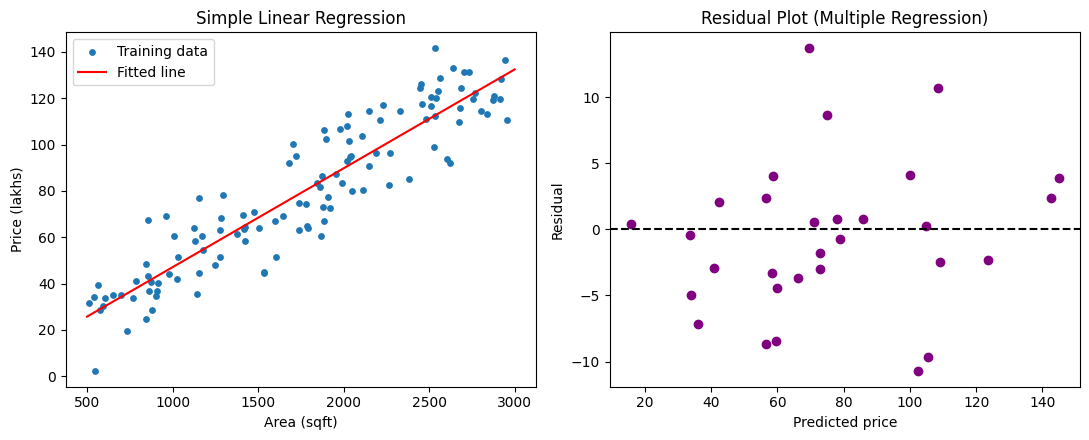

In [ ]:
#19-11-2026
#exp 5
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create dataset
np.random.seed(10)
n = 150

area = np.random.randint(500, 3000, n)
bedrooms = np.random.randint(1, 5, n)
age = np.random.randint(0, 30, n)
distance = np.round(np.random.uniform(1, 25, n), 1)

price = (
    15
    + 0.045 * area
    + 4 * bedrooms
    - 0.6 * age
    - 1.2 * distance
    + np.random.normal(0, 6, n)
)

# Create DataFrame
houses = pd.DataFrame(
    {
        "area_sqft": area,
        "bedrooms": bedrooms,
        "age_years": age,
        "distance_km": distance,
        "price_lakhs": price.round(2),
    }
)

# Display dataset
print("House Price Prediction using Linear Regression")
print("=" * 50)
print(houses.head().to_string(index=False))

# Correlation
print("\nCorrelation with price:")
print(
    houses.corr()["price_lakhs"]
    .drop("price_lakhs")
    .round(3)
    .to_string()
)

# Separate input and output
X = houses.drop(columns="price_lakhs")
y = houses["price_lakhs"]

# Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

# Simple Linear Regression
simple = LinearRegression().fit(
    X_train[["area_sqft"]], y_train
)

print("\nSimple Linear Regression: price = b0 + b1 * area")
print(f" b0 (intercept) = {simple.intercept_:.4f}")
print(f" b1 (slope)     = {simple.coef_[0]:.4f}")

print(
    f" R^2 on test    = "
    f"{r2_score(y_test, simple.predict(X_test[['area_sqft']])):.4f}"
)

# Multiple Linear Regression
model = LinearRegression().fit(X_train, y_train)

print("\nMultiple Linear Regression coefficients:")
print(f" {'Intercept':<12} {model.intercept_:>9.4f}")

for name, c in zip(X.columns, model.coef_):
    print(f" {name:<12} {c:>9.4f}")

# Model prediction
pred = model.predict(X_test)

# Model evaluation
mse = mean_squared_error(y_test, pred)

print("\nModel evaluation on test set:")
print(f" MAE  = {mean_absolute_error(y_test, pred):.4f}")
print(f" MSE  = {mse:.4f}")
print(f" RMSE = {np.sqrt(mse):.4f}")
print(f" R^2  = {r2_score(y_test, pred):.4f}")

# Predict new house price
new_house = pd.DataFrame(
    [[1800, 3, 5, 8.0]],
    columns=X.columns
)

print(
    "\nPredicted price for 1800 sqft, 3 BHK, 5 yrs old, 8 km away:",
    f"{model.predict(new_house)[0]:.2f} lakhs",
)

# Plot graphs
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

# Simple Linear Regression graph
xs = np.linspace(500, 3000, 100).reshape(-1, 1)

ax[0].scatter(
    X_train["area_sqft"],
    y_train,
    s=15,
    label="Training data"
)

ax[0].plot(
    xs,
    simple.predict(
        pd.DataFrame(xs, columns=["area_sqft"])
    ),
    color="red",
    label="Fitted line"
)

ax[0].set_xlabel("Area (sqft)")
ax[0].set_ylabel("Price (lakhs)")
ax[0].set_title("Simple Linear Regression")
ax[0].legend()

# Residual Plot
ax[1].scatter(pred, y_test - pred, color="purple")
ax[1].axhline(0, color="black", linestyle="--")
ax[1].set_xlabel("Predicted price")
ax[1].set_ylabel("Residual")
ax[1].set_title("Residual Plot (Multiple Regression)")

plt.tight_layout()
plt.savefig("exp05_regression.png", dpi=150)
plt.show()

Telecom Customer Churn Prediction using Logistic Regression
 tenure_months  monthly_bill  complaints  yearly_contract  churn
            25         451.0           0                1      0
             4        1144.0           2                0      1
            57         907.0           0                1      0
             1         895.0           3                1      1
            22         804.0           2                0      1

Churn distribution: {0: 275, 1: 125}

Coefficients (standardised features):
 tenure_months     -0.9840    odds ratio = 0.374
 monthly_bill       0.5949    odds ratio = 1.813
 complaints         0.8709    odds ratio = 2.389
 yearly_contract   -0.3919    odds ratio = 0.676
 Intercept         -1.0822

Validation on test set:
 Accuracy  = 0.7600
 Precision = 0.7333
 Recall    = 0.3548
 F1-score  = 0.4783
 ROC-AUC   = 0.8401

Confusion Matrix [rows = actual, cols = predicted]:
[[65  4]
 [20 11]]

5-fold cross-validation accuracy: [0.8125 0.825  0.7

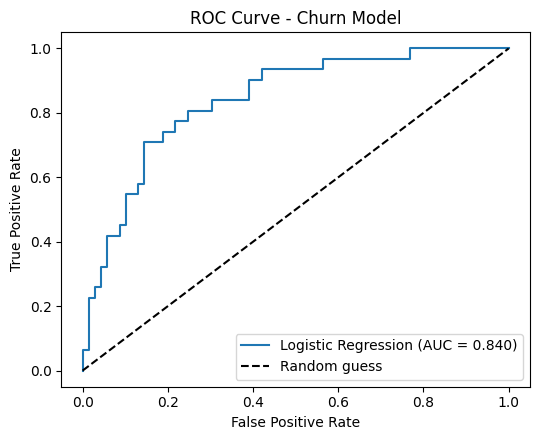

In [ ]:
#20-11-2026
#Exp 6
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)

# Create dataset
np.random.seed(3)
n = 400

tenure = np.random.randint(1, 72, n)
monthly = np.round(np.random.uniform(200, 1500, n), 0)
complaints = np.random.poisson(1.2, n)
contract = np.random.choice([0, 1], n, p=[0.55, 0.45])

# Calculate churn probability
logit = (
    -1.0
    - 0.06 * tenure
    + 0.002 * monthly
    + 0.7 * complaints
    - 1.3 * contract
)

churn = (
    np.random.rand(n) < 1 / (1 + np.exp(-logit))
).astype(int)

# Create DataFrame
data = pd.DataFrame(
    {
        "tenure_months": tenure,
        "monthly_bill": monthly,
        "complaints": complaints,
        "yearly_contract": contract,
        "churn": churn,
    }
)

# Display dataset
print("Telecom Customer Churn Prediction using Logistic Regression")
print("=" * 60)

print(data.head().to_string(index=False))

print(
    "\nChurn distribution:",
    data["churn"].value_counts().to_dict()
)

# Separate input and output
X = data.drop(columns="churn")
y = data["churn"]

# Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=0
)

# Create Logistic Regression model with StandardScaler
model = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)

# Train model
model.fit(X_train, y_train)

# Get Logistic Regression model
lr = model.named_steps["logisticregression"]

# Display coefficients and odds ratios
print("\nCoefficients (standardised features):")

for name, c in zip(X.columns, lr.coef_[0]):
    print(
        f" {name:<16} {c:>8.4f}    odds ratio = {np.exp(c):.3f}"
    )

print(f" {'Intercept':<16} {lr.intercept_[0]:>8.4f}")

# Predict test data
pred = model.predict(X_test)

# Calculate churn probabilities
prob = model.predict_proba(X_test)[:, 1]

# Model evaluation
print("\nValidation on test set:")

print(
    f" Accuracy  = {accuracy_score(y_test, pred):.4f}"
)

print(
    f" Precision = {precision_score(y_test, pred):.4f}"
)

print(
    f" Recall    = {recall_score(y_test, pred):.4f}"
)

print(
    f" F1-score  = {f1_score(y_test, pred):.4f}"
)

print(
    f" ROC-AUC   = {roc_auc_score(y_test, prob):.4f}"
)

# Confusion Matrix
print("\nConfusion Matrix [rows = actual, cols = predicted]:")

print(confusion_matrix(y_test, pred))

# 5-fold Cross Validation
cv = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring="accuracy"
)

print(
    "\n5-fold cross-validation accuracy:",
    np.round(cv, 4)
)

print(
    f"Mean = {cv.mean():.4f}, Std = {cv.std():.4f}"
)

# Predict new customer
customer = pd.DataFrame(
    [[4, 1250, 3, 0]],
    columns=X.columns
)

p = model.predict_proba(customer)[0, 1]

print(
    "\nNew customer (4 months, Rs.1250, 3 complaints, monthly plan):",
    f"churn probability = {p:.3f}",
)

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, prob)

plt.figure(figsize=(5.5, 4.5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc_score(y_test, prob):.3f})",
)

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random guess"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Churn Model")

plt.legend()
plt.tight_layout()

plt.savefig("exp06_roc.png", dpi=150)
plt.show()

In [ ]:
#20-11-2026
#Exp 7
import numpy as np
import pandas as pd

from sklearn.datasets import load_wine

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, export_text

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

# Load Wine dataset
wine = load_wine()

X = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

y = wine.target

# Display dataset information
print("Wine Quality Classification: Naive Bayes vs Memorization Methods")
print("=" * 65)

print(
    "Samples:",
    X.shape[0],
    "| Features:",
    X.shape[1],
    "| Classes:",
    list(wine.target_names),
)

print("Class counts:", np.bincount(y).tolist())

# Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

# Create classification models
models = {
    "Gaussian Naive Bayes": GaussianNB(),

    "k-Nearest Neighbours (k=5)": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Decision Tree (depth=3)": DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ),
}

# 5-fold cross validation
kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Model comparison
summary = []

for name, model in models.items():

    model.fit(X_train, y_train)

    train_acc = accuracy_score(
        y_train,
        model.predict(X_train)
    )

    test_acc = accuracy_score(
        y_test,
        model.predict(X_test)
    )

    cv = cross_val_score(
        model,
        X,
        y,
        cv=kfold
    )

    summary.append(
        [name, train_acc, test_acc, cv.mean(), cv.std()]
    )

# Display comparison table
table = pd.DataFrame(
    summary,
    columns=[
        "Model",
        "Train Acc",
        "Test Acc",
        "CV Mean",
        "CV Std"
    ]
)

print("\nModel comparison:")
print(table.round(4).to_string(index=False))

# Select best model
best = table.sort_values(
    ["CV Mean", "Test Acc"],
    ascending=False
).iloc[0]["Model"]

print("\nSelected model (highest CV accuracy):", best)

# Predict test data using selected model
pred = models[best].predict(X_test)

# Confusion Matrix
print("\nConfusion matrix of selected model:")
print(confusion_matrix(y_test, pred))

# Classification Report
print("\nClassification report:")
print(
    classification_report(
        y_test,
        pred,
        target_names=wine.target_names
    )
)

# Effect of k in KNN
print("Effect of k on kNN (5-fold CV accuracy):")

for k in [1, 3, 5, 7, 11, 15]:

    knn = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    print(
        f" k = {k:>2} -> "
        f"{cross_val_score(knn, X, y, cv=kfold).mean():.4f}"
    )

# Decision Tree Rules
print("\nDecision tree rules:")

print(
    export_text(
        models["Decision Tree (depth=3)"],
        feature_names=list(X.columns)
    )
)

Wine Quality Classification: Naive Bayes vs Memorization Methods
Samples: 178 | Features: 13 | Classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]
Class counts: [59, 71, 48]

Model comparison:
                     Model  Train Acc  Test Acc  CV Mean  CV Std
      Gaussian Naive Bayes     0.9677    1.0000   0.9719  0.0252
k-Nearest Neighbours (k=5)     0.9839    0.9444   0.9717  0.0181
   Decision Tree (depth=3)     0.9919    0.9630   0.8763  0.0465

Selected model (highest CV accuracy): Gaussian Naive Bayes

Confusion matrix of selected model:
[[18  0  0]
 [ 0 21  0]
 [ 0  0 15]]

Classification report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       1.00      1.00      1.00        21
     class_2       1.00      1.00      1.00        15

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00  

Mall Customer Segmentation using K-Means Clustering
 customer_id  annual_income_k  spending_score
           1             28.1            77.7
           2             42.0            78.2
           3             25.8            91.1
           4             18.6            75.9
           5             26.3            77.7
Total customers: 200

 k     WCSS     Silhouette
 2   219.83    0.4884
 3   100.85    0.5802
 4    49.31    0.5993
 5    28.97    0.6140
 6    23.86    0.5865
 7    21.52    0.5107
 8    19.23    0.4817

Best k by silhouette score: 5

Cluster profiles:
         annual_income_k  spending_score  size                      segment
cluster                                                                    
0                   25.3            20.4    40      Low income, low spender
1                   24.5            81.5    40     Low income, high spender
2                   84.0            84.5    40    High income, high spender
3                   55.2            21.

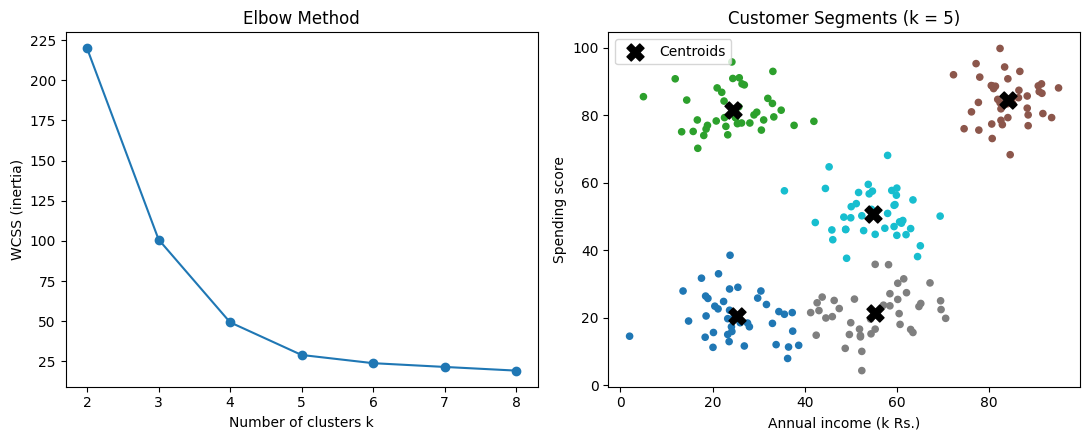

In [ ]:
#20-11-2026
#Exp 8
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

np.random.seed(5)

centres = [(25, 80), (55, 20), (85, 85), (55, 50), (25, 20)]
rows = []

for i, (inc, score) in enumerate(centres):
    for _ in range(40):
        rows.append([
            np.random.normal(inc, 7),
            np.random.normal(score, 7)
        ])

customers = pd.DataFrame(
    np.round(rows, 1),
    columns=["annual_income_k", "spending_score"]
)

customers.insert(0, "customer_id", range(1, len(customers) + 1))

print("Mall Customer Segmentation using K-Means Clustering")
print("=" * 52)
print(customers.head().to_string(index=False))
print("Total customers:", len(customers))

X = StandardScaler().fit_transform(
    customers[["annual_income_k", "spending_score"]]
)

# ---------- Choosing k: elbow (WCSS) and silhouette ----------

print("\n k     WCSS     Silhouette")

wcss, sil = [], []

for k in range(2, 9):
    km = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=0
    ).fit(X)

    wcss.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

    print(f"{k:>2} {km.inertia_:>8.2f}    {sil[-1]:.4f}")

best_k = range(2, 9)[int(np.argmax(sil))]

print("\nBest k by silhouette score:", best_k)

# ---------- Final model ----------

km = KMeans(
    n_clusters=best_k,
    n_init=10,
    random_state=0
).fit(X)

customers["cluster"] = km.labels_

profile = (
    customers.groupby("cluster")[
        ["annual_income_k", "spending_score"]
    ]
    .mean()
    .round(1)
)

profile["size"] = customers["cluster"].value_counts().sort_index()


def describe(row):
    inc = (
        "High income"
        if row.annual_income_k > 70
        else "Low income"
        if row.annual_income_k < 40
        else "Mid income"
    )

    sp = (
        "high spender"
        if row.spending_score > 65
        else "low spender"
        if row.spending_score < 35
        else "average spender"
    )

    return f"{inc}, {sp}"


profile["segment"] = profile.apply(describe, axis=1)

print("\nCluster profiles:")
print(profile.to_string())

# ---------- Plotting ----------

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

ax[0].plot(range(2, 9), wcss, "o-")
ax[0].set_xlabel("Number of clusters k")
ax[0].set_ylabel("WCSS (inertia)")
ax[0].set_title("Elbow Method")

sc = ax[1].scatter(
    customers["annual_income_k"],
    customers["spending_score"],
    c=customers["cluster"],
    cmap="tab10",
    s=20
)

centres = customers.groupby("cluster")[
    ["annual_income_k", "spending_score"]
].mean()

ax[1].scatter(
    centres.iloc[:, 0],
    centres.iloc[:, 1],
    c="black",
    marker="X",
    s=150,
    label="Centroids"
)

ax[1].set_xlabel("Annual income (k Rs.)")
ax[1].set_ylabel("Spending score")
ax[1].set_title(f"Customer Segments (k = {best_k})")
ax[1].legend()

plt.tight_layout()
plt.savefig("exp08_kmeans.png", dpi=150)
plt.show()

In [ ]:
#21-11-2026
#Exp 9
# ---------- Variables and basic data types ----------

hospital = "City Care Clinic"
patients_today = 4
consultation_fee = 350.0
is_open = True
emergency_contact = None
complex_reading = 3 + 4j

print("Patient Health Indicator System")
print("=" * 40)

print("Variables and their types:")

for name, value in [
    ("hospital", hospital),
    ("patients_today", patients_today),
    ("consultation_fee", consultation_fee),
    ("is_open", is_open),
    ("emergency_contact", emergency_contact),
    ("complex_reading", complex_reading),
]:
    print(f" {name:<18} = {str(value):<18} type = {type(value).__name__}")


# ---------- Expressions and operators ----------

print("\nExpressions:")

print(" Total fee (arithmetic)         :", patients_today * consultation_fee)
print(" 17 // 5, 17 % 5, 2 ** 10       :", 17 // 5, 17 % 5, 2**10)
print(" Fee > 300 and clinic open      :", consultation_fee > 300 and is_open)
print(" Type conversion int('45') + 5 :", int("45") + 5)
print(" abs(complex_reading)           :", abs(complex_reading))


# ---------- Functions ----------

def bmi(weight_kg, height_m):
    """Return Body Mass Index rounded to 2 decimals."""
    return round(weight_kg / height_m**2, 2)


def bmi_category(value):
    if value < 18.5:
        return "Underweight"
    elif value < 25:
        return "Normal"
    elif value < 30:
        return "Overweight"
    return "Obese"


def bp_status(systolic, diastolic=80):
    if systolic >= 140 or diastolic >= 90:
        return "High"
    if systolic < 90 or diastolic < 60:
        return "Low"
    return "Normal"


def average(*values):
    return round(sum(values) / len(values), 2)


def summary(**details):
    return ", ".join(f"{k}={v}" for k, v in details.items())


risk_score = lambda age, bmi_val: round(0.03 * age + 0.05 * bmi_val, 2)


# ---------- Objects (class) ----------

class Patient:
    count = 0

    def __init__(self, name, age, weight, height, systolic, diastolic):
        self.name, self.age = name, age
        self.weight, self.height = weight, height
        self.systolic, self.diastolic = systolic, diastolic
        Patient.count += 1

    def report(self):
        b = bmi(self.weight, self.height)

        return (
            f"{self.name:<8} Age {self.age:>2} | BMI {b:>5} ({bmi_category(b):<11}) | "
            f"BP {self.systolic}/{self.diastolic} "
            f"({bp_status(self.systolic, self.diastolic)}) | "
            f"Risk {risk_score(self.age, b)}"
        )

    def __str__(self):
        return f"Patient({self.name}, {self.age})"


patients = [
    Patient("Arun", 52, 82, 1.70, 145, 92),
    Patient("Sneha", 28, 54, 1.62, 112, 74),
    Patient("Gopal", 65, 60, 1.68, 88, 58),
    Patient("Nisha", 41, 95, 1.60, 130, 85),
]


print("\nPatient reports (objects + functions):")

for p in patients:
    print(" ", p.report())


print("\nObjects created     :", Patient.count)
print("str() of an object :", patients[0])
print("isinstance check    :", isinstance(patients[0], Patient))
print("Average age (*args) :", average(*[p.age for p in patients]))

print(
    "Summary (**kwargs) :",
    summary(clinic=hospital, patients=Patient.count, fee=consultation_fee),
)

print("bp_status(120) uses default diastolic ->", bp_status(120))
print("Docstring of bmi() :", bmi.__doc__)

Patient Health Indicator System
Variables and their types:
 hospital           = City Care Clinic   type = str
 patients_today     = 4                  type = int
 consultation_fee   = 350.0              type = float
 is_open            = True               type = bool
 emergency_contact  = None               type = NoneType
 complex_reading    = (3+4j)             type = complex

Expressions:
 Total fee (arithmetic)         : 1400.0
 17 // 5, 17 % 5, 2 ** 10       : 3 2 1024
 Fee > 300 and clinic open      : True
 Type conversion int('45') + 5 : 50
 abs(complex_reading)           : 5.0

Patient reports (objects + functions):
  Arun     Age 52 | BMI 28.37 (Overweight ) | BP 145/92 (High) | Risk 2.98
  Sneha    Age 28 | BMI 20.58 (Normal     ) | BP 112/74 (Normal) | Risk 1.87
  Gopal    Age 65 | BMI 21.26 (Normal     ) | BP 88/58 (Low) | Risk 3.01
  Nisha    Age 41 | BMI 37.11 (Obese      ) | BP 130/85 (Normal) | Risk 3.09

Objects created     : 4
str() of an object : Patient(Arun, 52)


In [ ]:
#21-11-2026
#Exp 10
import array
import re
import numpy as np

reviews = [
    " Excellent product! Battery life is GREAT and delivery was fast. ",
    "Poor quality. The battery drained in 2 hours. Very disappointed!!",
    "Good value for money, but the charger is slow.",
    "Delivery was late; product is average. Contact: support@shopmart.in",
    "Great camera, great display, great price!",
]

print("Customer Review and Sensor Analytics: Strings and Arrays")
print("=" * 58)

# ---------- Part A: String operations ----------
r = reviews[0]
print("\nPart A - String operations on review 1")
print(" Original           :", repr(r))
print(" strip()            :", r.strip())
print(" lower()            :", r.strip().lower())
print(" upper()            :", r.strip().upper())
print(" Length             :", len(r.strip()))
print(" Slice [0:17]       :", r.strip()[0:17])
print(" Reverse [::-1]     :", r.strip()[::-1][:25], "...")
print(" find('Battery')    :", r.strip().find("Battery"))
print(" count('a')         :", r.lower().count("a"))
print(" replace            :", r.strip().replace("GREAT", "good"))
print(" split()            :", r.strip().split()[:5], "...")
print(" startswith('Exc') :", r.strip().startswith("Exc"))

positive = {"excellent", "great", "good", "fast"}
negative = {"poor", "disappointed", "slow", "late", "drained"}

print("\nSentiment of each review:")
for i, text in enumerate(reviews, 1):
    words = re.findall(r"[a-z]+", text.lower())
    score = sum(w in positive for w in words) - sum(w in negative for w in words)
    label = "Positive" if score > 0 else "Negative" if score < 0 else "Neutral"
    print(f" Review {i}: words={len(words):>2} score={score:>2} -> {label}")

emails = re.findall(r"[\w.]+@[\w.]+", " ".join(reviews))
print("\nEmail extracted with regex:", emails)
print("Joined keywords :", " | ".join(sorted(positive)))
print("Formatted string: {:<10}|{:^10}|{:>10}".format("left", "centre", "right"))

# ---------- Part B: Arrays ----------
print("\nPart B - Arrays of temperature sensor readings")

temps = array.array("f", [31.5, 32.0, 33.8, 35.2, 34.1, 30.9, 36.4])

print(" array module       :", temps.tolist())

temps.append(37.0)
temps.insert(0, 30.2)

print(" after append/insert:", [round(t, 1) for t in temps])

print(
    " index of max       :",
    temps.index(max(temps)),
    "| typecode:",
    temps.typecode,
)

week = np.array(
    [
        [31.5, 32.0, 33.8, 35.2, 34.1, 30.9, 36.4],
        [29.8, 30.5, 31.2, 33.0, 32.7, 29.5, 34.0],
        [33.1, 34.2, 35.6, 37.1, 36.0, 32.8, 38.2],
    ]
)

print("\n NumPy 2-D array (3 sensors x 7 days):")
print(week)
print(" shape, ndim, size :", week.shape, week.ndim, week.size)
print(" Sensor means       :", week.mean(axis=1).round(2))
print(" Daily maximum      :", week.max(axis=0))
print(" Readings > 35      :", week[week > 35])
print(" Sensor 2, days 2-4:", week[1, 1:4])

print(" In Fahrenheit (vectorised):")
print((week * 9 / 5 + 32).round(1))

print(" Reshape to 7x3     :", week.reshape(7, 3).shape)
print(" Sorted sensor 1    :", np.sort(week[0]))

Customer Review and Sensor Analytics: Strings and Arrays

Part A - String operations on review 1
 Original           : ' Excellent product! Battery life is GREAT and delivery was fast. '
 strip()            : Excellent product! Battery life is GREAT and delivery was fast.
 lower()            : excellent product! battery life is great and delivery was fast.
 upper()            : EXCELLENT PRODUCT! BATTERY LIFE IS GREAT AND DELIVERY WAS FAST.
 Length             : 63
 Slice [0:17]       : Excellent product
 Reverse [::-1]     : .tsaf saw yreviled dna TA ...
 find('Battery')    : 19
 count('a')         : 5
 replace            : Excellent product! Battery life is good and delivery was fast.
 split()            : ['Excellent', 'product!', 'Battery', 'life', 'is'] ...
 startswith('Exc') : True

Sentiment of each review:
 Review 1: words=10 score= 3 -> Positive
 Review 2: words= 9 score=-3 -> Negative
 Review 3: words= 9 score= 0 -> Neutral
 Review 4: words=10 score=-1 -> Negative
 Review 5: 

In [ ]:
#21-11-2026
#Exp 11
print("Pharmacy Inventory Management: Lists and Tuples")
print("=" * 50)

# ---------- Tuples: fixed product records (immutable) ----------
# (product_code, name, unit_price)

products = (
    ("P101", "Paracetamol", 25.0),
    ("P102", "Amoxicillin", 120.0),
    ("P103", "Cetirizine", 40.0),
    ("P104", "Vitamin D3", 210.0),
    ("P105", "Insulin", 450.0),
)

print("\nProduct catalogue (tuple of tuples):")

for code, name, price in products:  # tuple unpacking
    print(f" {code} {name:<12} Rs.{price:>7.2f}")

print("Number of products :", len(products))
print("Second product      :", products[1])
print("Codes (slice)       :", tuple(p[0] for p in products[:3]))

print(
    "Count / index      :",
    products.count(products[0]),
    "/",
    products.index(("P103", "Cetirizine", 40.0)),
)

try:
    products[0][2] = 30.0
except TypeError as e:
    print("Attempt to change a tuple ->", "TypeError:", e)


# ---------- Lists: stock that changes every day ----------

stock = [120, 35, 80, 15, 8]

print("\nInitial stock list :", stock)

stock[3] += 50  # update by index

print("After restocking P104 (+50):", stock)

sold_today = [20, 10, 5, 12, 3]

stock = [s - d for s, d in zip(stock, sold_today)]  # list comprehension

print("After today's sales:", stock)

expiring = ["Amoxicillin", "Insulin"]

expiring.append("Cetirizine")
expiring.extend(["Paracetamol"])
expiring.insert(0, "Vitamin D3")

print("\nExpiring list after append/extend/insert:", expiring)

expiring.remove("Paracetamol")
last = expiring.pop()

print("After remove('Paracetamol') and pop() ->", expiring, "| popped:", last)

expiring.sort()
print("Sorted             :", expiring)

expiring.reverse()
print("Reversed           :", expiring)


# ---------- Combining lists and tuples ----------

inventory = [
    (code, name, price, qty)
    for (code, name, price), qty in zip(products, stock)
]

reorder = [
    name for _, name, _, qty in inventory if qty < 30
]

value = [
    round(price * qty, 2)
    for _, _, price, qty in inventory
]

print("\nInventory records (list of tuples):")

for item, v in zip(inventory, value):
    print(f" {item} stock value = Rs.{v:,.2f}")

print("Items to reorder (qty < 30):", reorder)
print("Total stock value : Rs.{:,.2f}".format(sum(value)))
print("Max / Min quantity :", max(stock), "/", min(stock))

by_value = sorted(
    inventory,
    key=lambda t: t[2] * t[3],
    reverse=True
)

print("Highest value item :", by_value[0][1])


# ---------- Nested list as a weekly sales matrix ----------

weekly = [
    [20, 10, 5, 12, 3],
    [18, 8, 7, 10, 2],
    [25, 12, 6, 9, 4]
]

totals = [
    sum(day[i] for day in weekly)
    for i in range(len(products))
]

print("\nWeekly sales matrix (3 days x 5 products):", weekly)

print(
    "Units sold per product:",
    dict(zip([p[1] for p in products], totals))
)

copy_list = stock.copy()
copy_list.clear()

print("Copied then cleared list:", copy_list, "| original stock still:", stock)

Pharmacy Inventory Management: Lists and Tuples

Product catalogue (tuple of tuples):
 P101 Paracetamol  Rs.  25.00
 P102 Amoxicillin  Rs. 120.00
 P103 Cetirizine   Rs.  40.00
 P104 Vitamin D3   Rs. 210.00
 P105 Insulin      Rs. 450.00
Number of products : 5
Second product      : ('P102', 'Amoxicillin', 120.0)
Codes (slice)       : ('P101', 'P102', 'P103')
Count / index      : 1 / 2
Attempt to change a tuple -> TypeError: 'tuple' object does not support item assignment

Initial stock list : [120, 35, 80, 15, 8]
After restocking P104 (+50): [120, 35, 80, 65, 8]
After today's sales: [100, 25, 75, 53, 5]

Expiring list after append/extend/insert: ['Vitamin D3', 'Amoxicillin', 'Insulin', 'Cetirizine', 'Paracetamol']
After remove('Paracetamol') and pop() -> ['Vitamin D3', 'Amoxicillin', 'Insulin'] | popped: Cetirizine
Sorted             : ['Amoxicillin', 'Insulin', 'Vitamin D3']
Reversed           : ['Vitamin D3', 'Insulin', 'Amoxicillin']

Inventory records (list of tuples):
 ('P101', 'Par

In [ ]:
#23-11-2026
#Exp 12
from collections import Counter, defaultdict

print("University Course Enrolment Analysis: Sets and Dictionaries")
print("=" * 60)

# ---------- Sets ----------

python_course = {"Anu", "Bala", "Chitra", "Dinesh", "Esha", "Farhan"}
ml_course = {"Chitra", "Dinesh", "Gokul", "Harini", "Esha"}
big_data = {"Bala", "Esha", "Harini", "Ishaan"}

print("\nPython course :", sorted(python_course))
print("ML course     :", sorted(ml_course))
print("Big Data      :", sorted(big_data))

print(
    "\nUnion (all students)          :",
    sorted(python_course | ml_course | big_data),
)

print("Intersection (Python & ML)    :", sorted(python_course & ml_course))
print("Difference (Python only, not ML):", sorted(python_course - ml_course))
print("Symmetric difference (Py ^ ML):", sorted(python_course ^ ml_course))

print(
    "In all three courses          :",
    sorted(python_course & ml_course & big_data),
)

print(
    "Is {'Esha','Bala'} subset of Python? :",
    {"Esha", "Bala"}.issubset(python_course),
)

print("Are ML and Big Data disjoint?        :", ml_course.isdisjoint(big_data))

ml_course.add("Jaya")
ml_course.discard("Gokul")

print("ML after add('Jaya'), discard('Gokul'):", sorted(ml_course))

duplicates = ["Anu", "Bala", "Anu", "Chitra", "Bala", "Anu"]

print("Unique names from a list with duplicates:", sorted(set(duplicates)))


# ---------- Dictionaries ----------

marks = {
    "Anu": {"Python": 88, "ML": None},
    "Bala": {"Python": 72, "BigData": 81},
    "Chitra": {"Python": 95, "ML": 91},
    "Dinesh": {"Python": 64, "ML": 70},
}

marks["Anu"]["ML"] = 79  # update nested value

marks["Esha"] = {
    "Python": 85,
    "ML": 88,
    "BigData": 90
}  # insert

print("\nStudent marks dictionary:")

for student, sub in marks.items():
    print(f" {student:<7} {sub}")

print("\nKeys   :", list(marks.keys()))
print("Chitra's Python mark   :", marks["Chitra"]["Python"])
print("get() for missing key :", marks.get("Zara", "Not enrolled"))

averages = {
    s: round(sum(v.values()) / len(v), 2)
    for s, v in marks.items()
}  # dictionary comprehension

print("Average per student    :", averages)

topper = max(averages, key=averages.get)

print("Topper                 :", topper, averages[topper])


# ---------- Subject-wise statistics ----------

subject_scores = defaultdict(list)

for sub in marks.values():
    for subject, m in sub.items():
        subject_scores[subject].append(m)

print("\nSubject-wise statistics:")

for subject, scores in subject_scores.items():
    print(
        f" {subject:<8} count={len(scores)} "
        f"avg={sum(scores)/len(scores):.2f}   max={max(scores)}"
    )


# ---------- Removing and updating dictionary ----------

removed = marks.pop("Dinesh")

print("\nRemoved Dinesh ->", removed, "| students left:", len(marks))

marks.update({"Farhan": {"Python": 77}})

print("After update() with Farhan:", sorted(marks))


# ---------- Word frequency using Counter ----------

feedback = (
    "good course good faculty excellent labs good projects excellent support"
)

freq = Counter(feedback.split())

print("\nWord frequency of feedback:", dict(freq))
print("Most common 2 words       :", freq.most_common(2))

print(
    "Sorted by value (desc)   :",
    dict(sorted(freq.items(), key=lambda kv: kv[1], reverse=True)),
)

University Course Enrolment Analysis: Sets and Dictionaries

Python course : ['Anu', 'Bala', 'Chitra', 'Dinesh', 'Esha', 'Farhan']
ML course     : ['Chitra', 'Dinesh', 'Esha', 'Gokul', 'Harini']
Big Data      : ['Bala', 'Esha', 'Harini', 'Ishaan']

Union (all students)          : ['Anu', 'Bala', 'Chitra', 'Dinesh', 'Esha', 'Farhan', 'Gokul', 'Harini', 'Ishaan']
Intersection (Python & ML)    : ['Chitra', 'Dinesh', 'Esha']
Difference (Python only, not ML): ['Anu', 'Bala', 'Farhan']
Symmetric difference (Py ^ ML): ['Anu', 'Bala', 'Farhan', 'Gokul', 'Harini']
In all three courses          : ['Esha']
Is {'Esha','Bala'} subset of Python? : True
Are ML and Big Data disjoint?        : False
ML after add('Jaya'), discard('Gokul'): ['Chitra', 'Dinesh', 'Esha', 'Harini', 'Jaya']
Unique names from a list with duplicates: ['Anu', 'Bala', 'Chitra']

Student marks dictionary:
 Anu     {'Python': 88, 'ML': 79}
 Bala    {'Python': 72, 'BigData': 81}
 Chitra  {'Python': 95, 'ML': 91}
 Dinesh  {'Python':

In [ ]:
#23-11-2026
#Exp 13
import hashlib
import itertools

BLOCK_SIZE = 64    # bytes (scaled down from HDFS default of 128 MB)
REPLICATION = 3


class DataNode:
    def __init__(self, name, rack):
        self.name, self.rack, self.alive = name, rack, True
        self.blocks = {}


class NameNode:
    """Keeps only metadata: file -> blocks, block -> DataNodes."""

    def __init__(self, datanodes):
        self.datanodes = datanodes
        self.namespace = {}  # path -> list of block ids
        self.block_map = {}  # block id -> list of DataNode names
        self._rr = itertools.cycle(range(len(datanodes)))
        self._next_id = 1

    def choose_targets(self):
        """Rack-aware: 1st replica on one rack, 2nd and 3rd on another rack."""
        live = [d for d in self.datanodes if d.alive]
        turn = next(self._rr)
        first = live[turn % len(live)]
        others = [d for d in live if d.rack != first.rack]
        second = others[turn % len(others)]
        third = [
            d for d in others if d.rack == second.rack and d is not second
        ][0]
        return [first, second, third]

    def put(self, path, data):
        ids = []
        for start in range(0, len(data), BLOCK_SIZE):
            chunk = data[start:start + BLOCK_SIZE]
            bid = f"blk_{self._next_id:04d}"
            self._next_id += 1
            targets = self.choose_targets()

            for dn in targets:  # replication pipeline
                dn.blocks[bid] = chunk

            self.block_map[bid] = [dn.name for dn in targets]
            ids.append(bid)

        self.namespace[path] = ids
        return ids

    def get(self, path):
        out = []
        for bid in self.namespace[path]:
            for name in self.block_map[bid]:
                dn = self.node(name)
                if dn.alive:  # read from first live replica
                    out.append(dn.blocks[bid])
                    break
        return "".join(out)

    def node(self, name):
        return next(d for d in self.datanodes if d.name == name)

    def handle_failure(self, name):
        failed = self.node(name)
        failed.alive = False
        repaired = 0

        for bid, holders in self.block_map.items():
            if name in holders:
                holders.remove(name)
                source = self.node(holders[0])
                spare = [
                    d for d in self.datanodes
                    if d.alive and d.name not in holders
                ][0]

                spare.blocks[bid] = source.blocks[bid]
                holders.append(spare.name)
                repaired += 1

        return repaired


def checksum(text):
    return hashlib.md5(text.encode()).hexdigest()[:8]


cluster = [
    DataNode("DN1", "Rack-1"),
    DataNode("DN2", "Rack-1"),
    DataNode("DN3", "Rack-1"),
    DataNode("DN4", "Rack-2"),
    DataNode("DN5", "Rack-2"),
    DataNode("DN6", "Rack-2"),
]

nn = NameNode(cluster)

log = "\n".join(
    f"2026-03-0{d} 10:{m:02d} sensor={s} temp={30 + (d * m + s) % 9}"
    for d in range(1, 3)
    for m in (5, 20)
    for s in (1, 2)
)

print("Distributed File System Simulation (HDFS)")
print("=" * 45)
print(f"Block size = {BLOCK_SIZE} bytes | Replication factor = {REPLICATION}")
print("Cluster    :", ", ".join(f"{d.name}({d.rack})" for d in cluster))

print("\n$ hdfs dfs -put sensor_log.txt /data/sensor_log.txt")
blocks = nn.put("/data/sensor_log.txt", log)
print(f"File size = {len(log)} bytes -> {len(blocks)} blocks")

print("\nNameNode metadata (block -> DataNodes):")
for bid in blocks:
    racks = {nn.node(n).rack for n in nn.block_map[bid]}
    print(f" {bid} {nn.block_map[bid]} racks={sorted(racks)}")

print("\nDataNode storage report:")
for d in cluster:
    print(f" {d.name} blocks={sorted(d.blocks)}")

print("\n$ hdfs dfs -cat /data/sensor_log.txt | head -3")
data = nn.get("/data/sensor_log.txt")
print("\n".join(data.splitlines()[:3]))
print("Checksum original =", checksum(log), "| read back =", checksum(data))

print("\n*** DataNode DN1 fails (heartbeat lost) ***")
fixed = nn.handle_failure("DN1")
print("Under-replicated blocks re-replicated:", fixed)

for bid in blocks:
    print(f" {bid} {nn.block_map[bid]}")

data2 = nn.get("/data/sensor_log.txt")
print(
    "File readable after failure:",
    data2 == log,
    "| checksum =",
    checksum(data2)
)

Distributed File System Simulation (HDFS)
Block size = 64 bytes | Replication factor = 3
Cluster    : DN1(Rack-1), DN2(Rack-1), DN3(Rack-1), DN4(Rack-2), DN5(Rack-2), DN6(Rack-2)

$ hdfs dfs -put sensor_log.txt /data/sensor_log.txt
File size = 271 bytes -> 5 blocks

NameNode metadata (block -> DataNodes):
 blk_0001 ['DN1', 'DN4', 'DN5'] racks=['Rack-1', 'Rack-2']
 blk_0002 ['DN2', 'DN5', 'DN4'] racks=['Rack-1', 'Rack-2']
 blk_0003 ['DN3', 'DN6', 'DN4'] racks=['Rack-1', 'Rack-2']
 blk_0004 ['DN4', 'DN1', 'DN2'] racks=['Rack-1', 'Rack-2']
 blk_0005 ['DN5', 'DN2', 'DN1'] racks=['Rack-1', 'Rack-2']

DataNode storage report:
 DN1 blocks=['blk_0001', 'blk_0004', 'blk_0005']
 DN2 blocks=['blk_0002', 'blk_0004', 'blk_0005']
 DN3 blocks=['blk_0003']
 DN4 blocks=['blk_0001', 'blk_0002', 'blk_0003', 'blk_0004']
 DN5 blocks=['blk_0001', 'blk_0002', 'blk_0005']
 DN6 blocks=['blk_0003']

$ hdfs dfs -cat /data/sensor_log.txt | head -3
2026-03-01 10:05 sensor=1 temp=36
2026-03-01 10:05 sensor=2 temp=3

In [ ]:
# 23-11-2026
# Exp 14
"""
Word count in Hadoop Streaming style.
  Local simulation : python exp14.py
  Hadoop Streaming : hadoop jar hadoop-streaming.jar \
                       -files exp14.py -mapper "python exp14.py map" \
                       -reducer "python exp14.py reduce" \
                       -input /data/news -output /out/wc
  Unix pipe test   : cat news.txt | python exp14.py map | sort | python exp14.py reduce
"""

import re
import sys
from itertools import groupby


def mapper(lines):
    for line in lines:
        for word in re.findall(r"[a-z]+", line.lower()):
            yield f"{word}\t1"


def reducer(lines):
    pairs = (line.rstrip("\n").split("\t") for line in lines)

    for word, group in groupby(pairs, key=lambda kv: kv[0]):
        yield f"{word}\t{sum(int(c) for _, c in group)}"


if len(sys.argv) > 1 and sys.argv[1] == "map":
    for out in mapper(sys.stdin):
        print(out)
    sys.exit()

if len(sys.argv) > 1 and sys.argv[1] == "reduce":
    for out in reducer(sys.stdin):
        print(out)
    sys.exit()


# ---------------- Local simulation of the Hadoop job ----------------

splits = {
    "split-1 (node1)": [
        "Data science uses data to create value",
        "Big data needs distributed storage",
    ],
    "split-2 (node2)": [
        "Hadoop stores big data in HDFS",
        "MapReduce processes data in parallel",
    ],
    "split-3 (node3)": [
        "Spark and Hadoop process big data",
        "Data drives science",
    ],
}

print("MapReduce Word Count on News Headlines")
print("=" * 42)

print("\n--- MAP PHASE ---")

mapped = {}

for split, lines in splits.items():
    out = list(mapper(lines))
    mapped[split] = out

    print(
        f"{split}: {len(out)} pairs ->",
        ", ".join(o.replace("\t", ":") for o in out[:6]),
        "...",
    )


print("\n--- COMBINER (local aggregation on each mapper) ---")

combined = []

for split, out in mapped.items():
    local = list(reducer(sorted(out)))
    combined.extend(local)

    print(f"{split}: {len(out)} pairs reduced to {len(local)}")


print("\n--- SHUFFLE AND SORT ---")

shuffled = sorted(combined)

for key, grp in groupby(shuffled, key=lambda s: s.split("\t")[0]):
    values = [g.split("\t")[1] for g in grp]

    if len(values) > 1:
        print(f" {key:<12} -> {values}")

print(" (keys appearing on only one mapper are not shown)")


print("\n--- REDUCE PHASE ---")

result = [r.split("\t") for r in reducer(shuffled)]

result.sort(key=lambda kv: (-int(kv[1]), kv[0]))

print(f"{'WORD':<12}COUNT")

for word, count in result:
    print(f"{word:<12}{count}")

print("\nDistinct words :", len(result))
print("Total words    :", sum(int(c) for _, c in result))
print("Top 3 words    :", [w for w, _ in result[:3]])


# Running the same file without a cluster or on Hadoop:
#
# Windows:
# type news.txt | python exp14.py map | sort | python exp14.py reduce
#
# Linux:
# cat news.txt | python exp14.py map | sort | python exp14.py reduce
#
# Hadoop:
# hadoop jar $HADOOP_HOME/share/hadoop/tools/lib/hadoop-streaming-*.jar \
# -files exp14.py \
# -mapper "python exp14.py map" \
# -reducer "python exp14.py reduce" \
# -input /data/news \
# -output /out/wc

MapReduce Word Count on News Headlines

--- MAP PHASE ---
split-1 (node1): 12 pairs -> data:1, science:1, uses:1, data:1, to:1, create:1 ...
split-2 (node2): 11 pairs -> hadoop:1, stores:1, big:1, data:1, in:1, hdfs:1 ...
split-3 (node3): 9 pairs -> spark:1, and:1, hadoop:1, process:1, big:1, data:1 ...

--- COMBINER (local aggregation on each mapper) ---
split-1 (node1): 12 pairs reduced to 10
split-2 (node2): 11 pairs reduced to 9
split-3 (node3): 9 pairs reduced to 8

--- SHUFFLE AND SORT ---
 big          -> ['1', '1', '1']
 data         -> ['2', '2', '3']
 hadoop       -> ['1', '1']
 science      -> ['1', '1']
 (keys appearing on only one mapper are not shown)

--- REDUCE PHASE ---
WORD        COUNT
data        7
big         3
hadoop      2
in          2
science     2
and         1
create      1
distributed 1
drives      1
hdfs        1
mapreduce   1
needs       1
parallel    1
process     1
processes   1
spark       1
storage     1
stores      1
to          1
uses        1
value 

In [ ]:
# 24-11-2026
#Exp 15
"""
Matrix-vector multiplication x = M.v with MapReduce (Hadoop Streaming style).
Input records : i<TAB>j<TAB>m_ij   (sparse matrix entries)
  Hadoop : -mapper "python exp15.py map" -reducer "python exp15.py reduce"
            -files exp15.py,vector.txt
"""

import sys
from itertools import groupby
import numpy as np


def load_vector(path="vector.txt"):
    with open(path) as f:
        return {
            int(j): float(v)
            for j, v in (line.split() for line in f)
        }


def mapper(lines, v):
    for line in lines:
        i, j, m = line.split()
        yield f"{int(i)}\t{float(m) * v[int(j)]}"


def reducer(lines):
    pairs = (l.rstrip("\n").split("\t") for l in lines)

    for i, grp in groupby(pairs, key=lambda kv: int(kv[0])):
        yield f"{i}\t{sum(float(x) for _, x in grp)}"


if len(sys.argv) > 1 and sys.argv[1] in ("map", "reduce"):
    if sys.argv[1] == "map":
        out = mapper(sys.stdin, load_vector())
    else:
        out = reducer(sys.stdin)

    for o in out:
        print(o)

    sys.exit()


# ---------------- Local simulation ----------------

# Link matrix of a 5-page website
# (column j = page j shares its rank equally among the pages it links to)

M = np.array(
    [
        [0, 0.5, 0, 0, 1 / 3],
        [1 / 3, 0, 0, 0.5, 0],
        [1 / 3, 0, 0, 0.5, 1 / 3],
        [1 / 3, 0, 1.0, 0, 1 / 3],
        [0, 0.5, 0, 0, 0],
    ]
)

v = np.array([0.2, 0.2, 0.2, 0.2, 0.2])

entries = [
    f"{i}\t{j}\t{M[i, j]}"
    for i in range(5)
    for j in range(5)
    if M[i, j] != 0
]

with open("matrix.txt", "w") as f:
    f.write("\n".join(entries))

with open("vector.txt", "w") as f:
    f.write("\n".join(f"{j} {val}" for j, val in enumerate(v)))

vec = load_vector()

print("Matrix-Vector Multiplication using MapReduce (PageRank step)")
print("=" * 60)
print("Matrix M (5 x 5):")
print(np.round(M, 3))
print("Vector v:", v)
print(f"Non-zero entries stored as (i, j, m_ij): {len(entries)} of {M.size}")

splits = [entries[:5], entries[5:]]

print("\n--- MAP PHASE: emit (i, m_ij * v_j) ---")

mapped = []

for s, chunk in enumerate(splits, 1):
    out = list(mapper(chunk, vec))
    mapped += out

    print(f"Mapper {s}:")

    for rec, o in zip(chunk, out):
        i, j, m = rec.split("\t")

        print(
            f" ({i},{j}, {float(m):.3f}) -> key {o.split()[0]}, "
            f"value {float(o.split()[1]):.4f}"
        )


print("\n--- SHUFFLE AND SORT: group values by row i ---")

shuffled = sorted(
    mapped,
    key=lambda s: int(s.split("\t")[0])
)

for i, grp in groupby(shuffled, key=lambda s: s.split("\t")[0]):
    print(
        f" row {i}: "
        f"{[round(float(g.split()[1]), 4) for g in grp]}"
    )


print("\n--- REDUCE PHASE: x_i = sum of values ---")

x = np.zeros(5)

for r in reducer(shuffled):
    i, val = r.split("\t")
    x[int(i)] = float(val)

    print(f" x[{i}] = {float(val):.4f}")


print("\nMapReduce result x :", np.round(x, 4))
print("NumPy check   M @ v :", np.round(M @ v, 4))
print("Results match       :", np.allclose(x, M @ v))


print("\nRepeating the job (power iteration) gives PageRank:")

r = v.copy()

for it in range(1, 31):
    r_new = M @ r

    if it in (1, 2, 5, 30):
        print(f" iteration {it:>2}: {np.round(r_new, 4)}")

    r = r_new

print("Most important page:", int(np.argmax(r)))

Matrix-Vector Multiplication using MapReduce (PageRank step)
Matrix M (5 x 5):
[[0.    0.5   0.    0.    0.333]
 [0.333 0.    0.    0.5   0.   ]
 [0.333 0.    0.    0.5   0.333]
 [0.333 0.    1.    0.    0.333]
 [0.    0.5   0.    0.    0.   ]]
Vector v: [0.2 0.2 0.2 0.2 0.2]
Non-zero entries stored as (i, j, m_ij): 11 of 25

--- MAP PHASE: emit (i, m_ij * v_j) ---
Mapper 1:
 (0,1, 0.500) -> key 0, value 0.1000
 (0,4, 0.333) -> key 0, value 0.0667
 (1,0, 0.333) -> key 1, value 0.0667
 (1,3, 0.500) -> key 1, value 0.1000
 (2,0, 0.333) -> key 2, value 0.0667
Mapper 2:
 (2,3, 0.500) -> key 2, value 0.1000
 (2,4, 0.333) -> key 2, value 0.0667
 (3,0, 0.333) -> key 3, value 0.0667
 (3,2, 1.000) -> key 3, value 0.2000
 (3,4, 0.333) -> key 3, value 0.0667
 (4,1, 0.500) -> key 4, value 0.1000

--- SHUFFLE AND SORT: group values by row i ---
 row 0: [0.1, 0.0667]
 row 1: [0.0667, 0.1]
 row 2: [0.0667, 0.1, 0.0667]
 row 3: [0.0667, 0.2, 0.0667]
 row 4: [0.1]

--- REDUCE PHASE: x_i = sum of values

In [ ]:
# 24-11-2026
#Exp 16
"""
Two chained MapReduce jobs (Hadoop Streaming style):
  Job 1 - reduce-side natural join of CUSTOMERS(cust_id, name, city)
          and ORDERS(order_id, cust_id, amount)
  Job 2 - grouping and aggregation: revenue, order count and maximum order per city
"""

from itertools import groupby

customers = [
    "C1,Kavya,Chennai",
    "C2,Ravi,Bengaluru",
    "C3,Sana,Chennai",
    "C4,Tarun,Hyderabad",
    "C5,Uma,Bengaluru",
]

orders = [
    "O1,C1,2500",
    "O2,C2,1800",
    "O3,C1,700",
    "O4,C3,4200",
    "O5,C4,1500",
    "O6,C2,3100",
    "O7,C5,950",
    "O8,C3,600",
    "O9,C9,800",
]


# ---------------- Job 1: Join ----------------

def join_mapper(source, line):
    f = line.split(",")

    if source == "customers":
        return f[0], ("C", f[1], f[2])

    return f[1], ("O", f[0], int(f[2]))


def join_reducer(cust_id, values):
    cust = [v for v in values if v[0] == "C"]
    ords = [v for v in values if v[0] == "O"]

    for c in cust:
        for o in ords:
            yield cust_id, c[1], c[2], o[1], o[2]


# ---------------- Job 2: Group by city ----------------

def agg_mapper(joined_row):
    _, _, city, _, amount = joined_row
    return city, amount


def agg_reducer(city, amounts):
    return city, sum(amounts), len(amounts), max(amounts)


def shuffle(pairs):
    pairs = sorted(pairs, key=lambda kv: kv[0])

    return [
        (k, [v for _, v in g])
        for k, g in groupby(pairs, key=lambda kv: kv[0])
    ]


print("Sales Analytics: Join and Aggregation using MapReduce")
print("=" * 55)


# ---------------- JOB 1: MAP ----------------

print("\nJOB 1 - MAP (key = cust_id, value tagged with relation):")

mapped = [
    join_mapper("customers", l) for l in customers
] + [
    join_mapper("orders", l) for l in orders
]

for k, v in mapped:
    print(f" {k} -> {v}")


# ---------------- JOB 1: SHUFFLE AND SORT ----------------

print("\nJOB 1 - SHUFFLE AND SORT:")

groups = shuffle(mapped)

for k, vals in groups:
    print(f" {k}: {vals}")


# ---------------- JOB 1: REDUCE ----------------

print("\nJOB 1 - REDUCE (joined records):")

joined = [
    row
    for k, vals in groups
    for row in join_reducer(k, vals)
]

print(f" {'cust':<5}{'name':<7}{'city':<11}{'order':<7}amount")

for row in joined:
    print(
        f" {row[0]:<5}{row[1]:<7}{row[2]:<11}"
        f"{row[3]:<7}{row[4]}"
    )

print(" Note: order O9 (cust C9) has no matching customer and is dropped.")


# ---------------- JOB 2: MAP ----------------

print("\nJOB 2 - MAP (key = city, value = amount):")

mapped2 = [agg_mapper(r) for r in joined]

print(" ", mapped2)


# ---------------- JOB 2: SHUFFLE AND SORT ----------------

print("\nJOB 2 - SHUFFLE AND SORT:")

groups2 = shuffle(mapped2)

for city, vals in groups2:
    print(f" {city}: {vals}")


# ---------------- JOB 2: REDUCE ----------------

print("\nJOB 2 - REDUCE (aggregates per city):")

print(
    f" {'City':<11}{'Revenue':>8}"
    f"{'Orders':>8}{'Max':>7}{'Avg':>9}"
)

results = [
    agg_reducer(c, v)
    for c, v in groups2
]

for city, total, cnt, mx in sorted(
    results,
    key=lambda r: -r[1]
):
    print(
        f" {city:<11}{total:>8}{cnt:>8}"
        f"{mx:>7}{total / cnt:>9.2f}"
    )

print("\nGrand total revenue:", sum(r[1] for r in results))

Sales Analytics: Join and Aggregation using MapReduce

JOB 1 - MAP (key = cust_id, value tagged with relation):
 C1 -> ('C', 'Kavya', 'Chennai')
 C2 -> ('C', 'Ravi', 'Bengaluru')
 C3 -> ('C', 'Sana', 'Chennai')
 C4 -> ('C', 'Tarun', 'Hyderabad')
 C5 -> ('C', 'Uma', 'Bengaluru')
 C1 -> ('O', 'O1', 2500)
 C2 -> ('O', 'O2', 1800)
 C1 -> ('O', 'O3', 700)
 C3 -> ('O', 'O4', 4200)
 C4 -> ('O', 'O5', 1500)
 C2 -> ('O', 'O6', 3100)
 C5 -> ('O', 'O7', 950)
 C3 -> ('O', 'O8', 600)
 C9 -> ('O', 'O9', 800)

JOB 1 - SHUFFLE AND SORT:
 C1: [('C', 'Kavya', 'Chennai'), ('O', 'O1', 2500), ('O', 'O3', 700)]
 C2: [('C', 'Ravi', 'Bengaluru'), ('O', 'O2', 1800), ('O', 'O6', 3100)]
 C3: [('C', 'Sana', 'Chennai'), ('O', 'O4', 4200), ('O', 'O8', 600)]
 C4: [('C', 'Tarun', 'Hyderabad'), ('O', 'O5', 1500)]
 C5: [('C', 'Uma', 'Bengaluru'), ('O', 'O7', 950)]
 C9: [('O', 'O9', 800)]

JOB 1 - REDUCE (joined records):
 cust name   city       order  amount
 C1   Kavya  Chennai    O1     2500
 C1   Kavya  Chennai    O

Monthly Sales Trend Analysis using Line Plots
            Electronics  Clothing  Groceries
2025-01-01        128.1      69.5      150.5
2025-02-01        128.4      66.4      153.3
2025-03-01        138.3      79.9      152.8
2025-04-01        141.6      89.8      151.0
2025-05-01        153.3     107.2      148.6
2025-06-01        136.0     121.8      152.6
...

Yearly totals (Rs. lakhs):
      Electronics  Clothing  Groceries
2025       1696.0    1159.6     1862.8
2026       2281.7    1410.5     1978.5

Peak Electronics month: Dec 2026 (207.0 lakhs)
Electronics trend line: sales = 125.62 + 3.49 * month_index


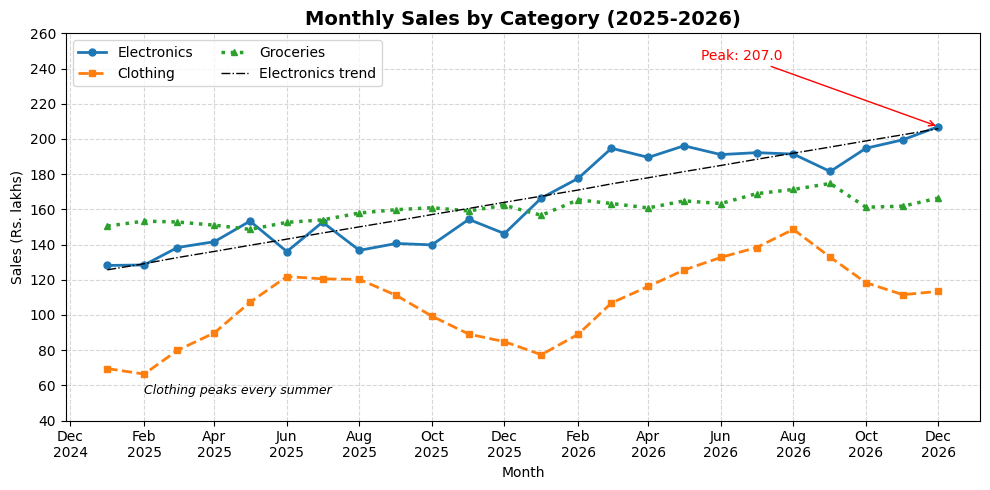

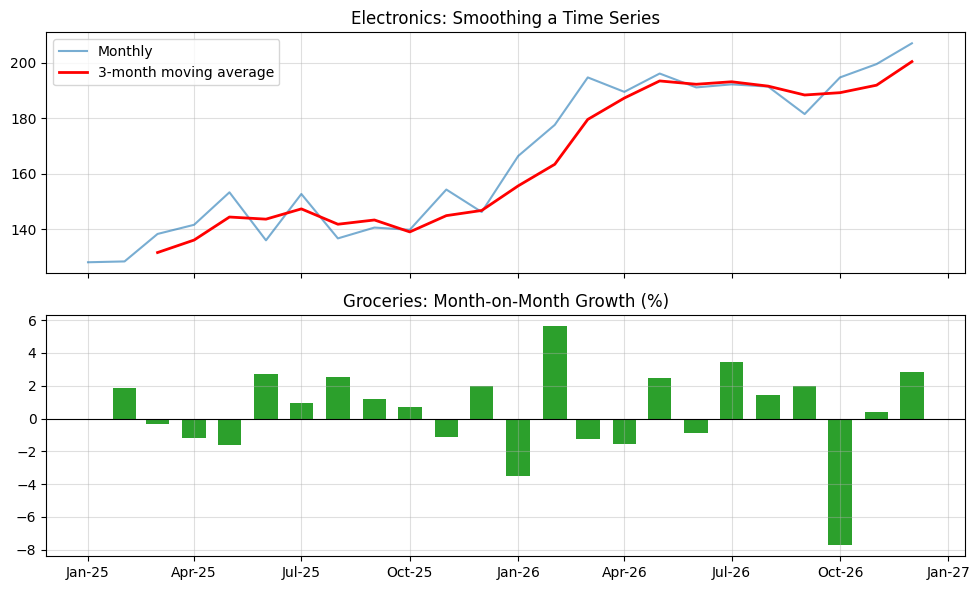


Saved figures: exp17_line.png, exp17_timeseries.png


In [ ]:
#24/11/2026
#EXP 17
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Set random seed for reproducible results
np.random.seed(1)

# Generate 24 months of dates starting from January 2025
months = pd.date_range("2025-01-01", periods=24, freq="MS")

# Create month index
t = np.arange(24)

# Generate monthly sales data for three categories
sales = pd.DataFrame(
    {
        # Electronics sales with increasing trend and seasonal variation
        "Electronics": 120 + 4.0 * t + 15 * np.sin(2 * np.pi * t / 12) + np.random.normal(0, 5, 24),

        # Clothing sales with seasonal variation
        "Clothing": 90 + 1.5 * t + 25 * np.sin(2 * np.pi * (t - 3) / 12) + np.random.normal(0, 5, 24),

        # Groceries sales with a gradual increasing trend
        "Groceries": 150 + 0.8 * t + np.random.normal(0, 4, 24),
    },
    index=months
).round(1)

# Display sales details
print("Monthly Sales Trend Analysis using Line Plots")
print("=" * 46)
print(sales.head(6).to_string())
print("...")

# Calculate and display yearly sales totals
print("\nYearly totals (Rs. lakhs):")
print(sales.groupby(sales.index.year).sum().round(1).to_string())

# Find the month with maximum Electronics sales
peak = sales["Electronics"].idxmax()

print(f"\nPeak Electronics month: {peak:%b %Y} ({sales['Electronics'].max()} lakhs)")

# Calculate linear trend line using least squares method
slope, intercept = np.polyfit(t, sales["Electronics"], 1)

print(f"Electronics trend line: sales = {intercept:.2f} + {slope:.2f} * month_index")

# Calculate 3-month moving average
rolling = sales["Electronics"].rolling(3).mean()

# ---------- Figure 1: Formatted multi-line chart ----------

# Create figure and axis
fig, ax = plt.subplots(figsize=(10, 5))

# Plot Electronics sales using blue solid line and circle markers
ax.plot(sales.index, sales["Electronics"], color="tab:blue",
        linestyle="-", linewidth=2, marker="o",
        markersize=5, label="Electronics")

# Plot Clothing sales using orange dashed line and square markers
ax.plot(sales.index, sales["Clothing"], color="tab:orange",
        linestyle="--", linewidth=2, marker="s",
        markersize=5, label="Clothing")

# Plot Groceries sales using green dotted line and triangle markers
ax.plot(sales.index, sales["Groceries"], color="tab:green",
        linestyle=":", linewidth=2.5, marker="^",
        markersize=5, label="Groceries")

# Draw the Electronics linear trend line
ax.plot(sales.index, intercept + slope * t,
        color="black", linestyle="-.", linewidth=1,
        label="Electronics trend")

# Set chart title and axis labels
ax.set_title("Monthly Sales by Category (2025-2026)",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Sales (Rs. lakhs)")

# Set Y-axis limits and tick values
ax.set_ylim(40, 260)
ax.set_yticks(range(40, 261, 20))

# Format X-axis dates
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))

# Display grid lines
ax.grid(True, which="major", linestyle="--", alpha=0.5)

# Annotate the peak Electronics sales with an arrow
ax.annotate(
    f"Peak: {sales['Electronics'].max()}",
    xy=(peak, sales["Electronics"].max()),
    xytext=(peak - pd.Timedelta(days=200), 245),
    arrowprops=dict(arrowstyle="->", color="red"),
    color="red"
)

# Add a text label inside the graph
ax.text(months[1], 55, "Clothing peaks every summer",
        fontsize=9, style="italic")

# Display legend
ax.legend(loc="upper left", ncol=2, frameon=True)

# Adjust layout and save figure
plt.tight_layout()
plt.savefig("exp17_line.png", dpi=150)

# ---------- Figure 2: Time-series smoothing and growth ----------

# Create two vertically arranged subplots
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Plot original Electronics monthly sales
axes[0].plot(sales.index, sales["Electronics"],
             label="Monthly", alpha=0.6)

# Plot 3-month moving average
axes[0].plot(sales.index, rolling,
             color="red", linewidth=2,
             label="3-month moving average")

# Set title, legend and grid
axes[0].set_title("Electronics: Smoothing a Time Series")
axes[0].legend()
axes[0].grid(alpha=0.4)

# Calculate month-on-month percentage growth
growth = sales.pct_change().mul(100)

# Display Groceries growth using a bar chart
axes[1].bar(sales.index, growth["Groceries"],
            width=20, color="tab:green")

# Draw horizontal zero reference line
axes[1].axhline(0, color="black", linewidth=0.8)

# Set title and grid
axes[1].set_title("Groceries: Month-on-Month Growth (%)")
axes[1].grid(alpha=0.4)

# Format date labels
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))

# Adjust layout, save and display charts
plt.tight_layout()
plt.savefig("exp17_timeseries.png", dpi=150)
plt.show()

# Display saved figure names
print("\nSaved figures: exp17_line.png, exp17_timeseries.png")


Hospital Operations Dashboard: Choosing the Right Graph

Budget share (%)       : {'Cardiology': 28, 'Orthopaedics': 18, 'Neurology': 22, 'Paediatrics': 12, 'General': 20}
Patients 2025 vs 2026 :
 Cardiology      820   910 change = +11.0%
 Orthopaedics    640   700 change = +9.4%
 Neurology       410   455 change = +11.0%
 Paediatrics     930   880 change = -5.4%
 General        1500  1620 change = +8.0%

Patient age: n = 1289, mean = 42.9, median = 46.3, std = 23.2

Waiting time (minutes) summary by department:
              mean   25%   50%   75%   max
Cardiology    17.6  10.2  15.7  23.2  48.7
Orthopaedics  15.5   8.7  14.3  20.6  41.5
Neurology     25.1  17.2  23.5  30.9  59.2
Paediatrics   11.1   4.3   8.1  14.7  46.5
General       29.8  21.1  28.1  37.4  69.1


/tmp/ipykernel_2936/236767503.py:115: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[1, 1].boxplot(


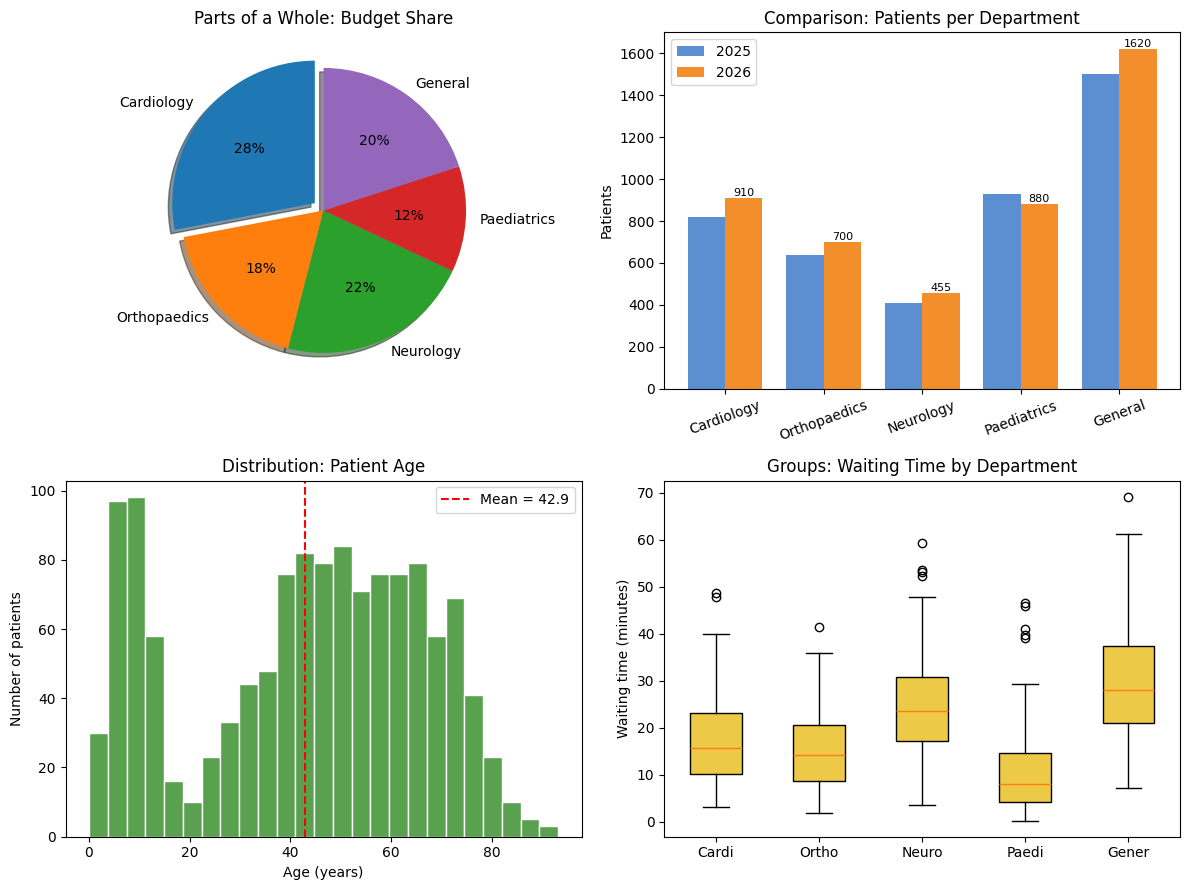


Saved figures: exp18_dashboard.png, exp18_barh.png


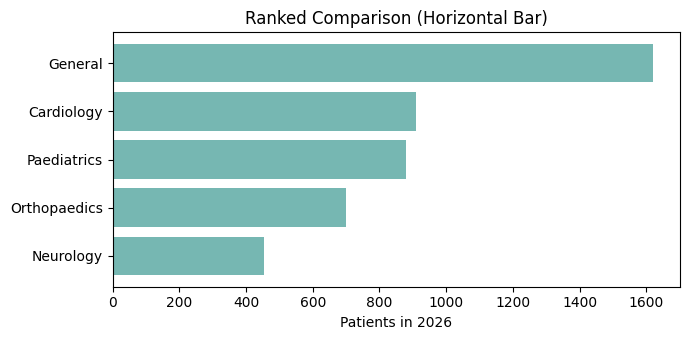

In [ ]:
#25/11/2026
#EXP 18
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(11)

departments = [
    "Cardiology",
    "Orthopaedics",
    "Neurology",
    "Paediatrics",
    "General"
]

budget_share = [28, 18, 22, 12, 20]
patients_2025 = [820, 640, 410, 930, 1500]
patients_2026 = [910, 700, 455, 880, 1620]

wait = {
    d: np.random.gamma(shape=k, scale=6, size=120)
    for d, k in zip(departments, [3, 2.5, 4, 1.8, 5])
}

ages = np.concatenate([
    np.random.normal(8, 4, 300),
    np.random.normal(45, 12, 700),
    np.random.normal(70, 8, 300)
])

ages = ages[(ages > 0) & (ages < 100)]

print("Hospital Operations Dashboard: Choosing the Right Graph")
print("=" * 56)

print("\nBudget share (%)       :", dict(zip(departments, budget_share)))
print("Patients 2025 vs 2026 :")

for d, a, b in zip(departments, patients_2025, patients_2026):
    print(f" {d:<13} {a:>5} {b:>5} change = {100 * (b - a) / a:+.1f}%")

print(
    "\nPatient age: n = {}, mean = {:.1f}, median = {:.1f}, std = {:.1f}".format(
        len(ages), ages.mean(), np.median(ages), ages.std()
    )
)

print("\nWaiting time (minutes) summary by department:")

summary = (
    pd.DataFrame(wait).describe().T[
        ["mean", "25%", "50%", "75%", "max"]
    ].round(1)
)

print(summary.to_string())

# Create dashboard
fig, ax = plt.subplots(2, 2, figsize=(12, 9))

# Pie chart
explode = [0.08 if s == max(budget_share) else 0 for s in budget_share]

ax[0, 0].pie(
    budget_share,
    labels=departments,
    autopct="%1.0f%%",
    startangle=90,
    explode=explode,
    shadow=True
)

ax[0, 0].set_title("Parts of a Whole: Budget Share")

# Grouped bar chart
x = np.arange(len(departments))
w = 0.38

b1 = ax[0, 1].bar(
    x - w / 2, patients_2025, w,
    label="2025", color="#5b8fd1"
)

b2 = ax[0, 1].bar(
    x + w / 2, patients_2026, w,
    label="2026", color="#f28e2b"
)

ax[0, 1].bar_label(b2, fontsize=8)
ax[0, 1].set_xticks(x, departments, rotation=20)
ax[0, 1].set_ylabel("Patients")
ax[0, 1].legend()
ax[0, 1].set_title("Comparison: Patients per Department")

# Histogram
ax[1, 0].hist(
    ages, bins=25,
    color="#59a14f", edgecolor="white"
)

ax[1, 0].axvline(
    ages.mean(),
    color="red",
    linestyle="--",
    label=f"Mean = {ages.mean():.1f}"
)

ax[1, 0].set_xlabel("Age (years)")
ax[1, 0].set_ylabel("Number of patients")
ax[1, 0].set_title("Distribution: Patient Age")
ax[1, 0].legend()

# Box plot
ax[1, 1].boxplot(
    wait.values(),
    labels=[d[:5] for d in departments],
    patch_artist=True,
    boxprops=dict(facecolor="#edc948")
)

ax[1, 1].set_ylabel("Waiting time (minutes)")
ax[1, 1].set_title("Groups: Waiting Time by Department")

plt.tight_layout()
plt.savefig("exp18_dashboard.png", dpi=150)
plt.show()

# Horizontal bar chart
fig, ax = plt.subplots(figsize=(7, 3.5))

order = np.argsort(patients_2026)

ax.barh(
    np.array(departments)[order],
    np.array(patients_2026)[order],
    color="#76b7b2"
)

ax.set_xlabel("Patients in 2026")
ax.set_title("Ranked Comparison (Horizontal Bar)")

plt.tight_layout()
plt.savefig("exp18_barh.png", dpi=150)

print("\nSaved figures: exp18_dashboard.png, exp18_barh.png")


Basemap not found. Install with: pip install basemap (or use Cartopy)
Air Quality Analysis: Scatterplots, Correlation and Geographic Data
         city  vehicles_lakh  industries  green_cover  pm25
        Delhi            122          55           12  88.4
       Mumbai             45          70           10  68.7
      Kolkata             40          60            8  53.1
      Chennai             62          58           14  74.4
    Bengaluru            105          45           16  66.1
    Hyderabad             77          50           12  65.8
    Ahmedabad             45          75            9  74.9
         Pune             40          52           15  47.3
       Jaipur             30          30           11  36.8
      Lucknow             28          28           10  76.7
       Kanpur             17          48            7  92.3
        Patna             18          22            6  89.3
       Bhopal             16          25           21  25.2
        Kochi         

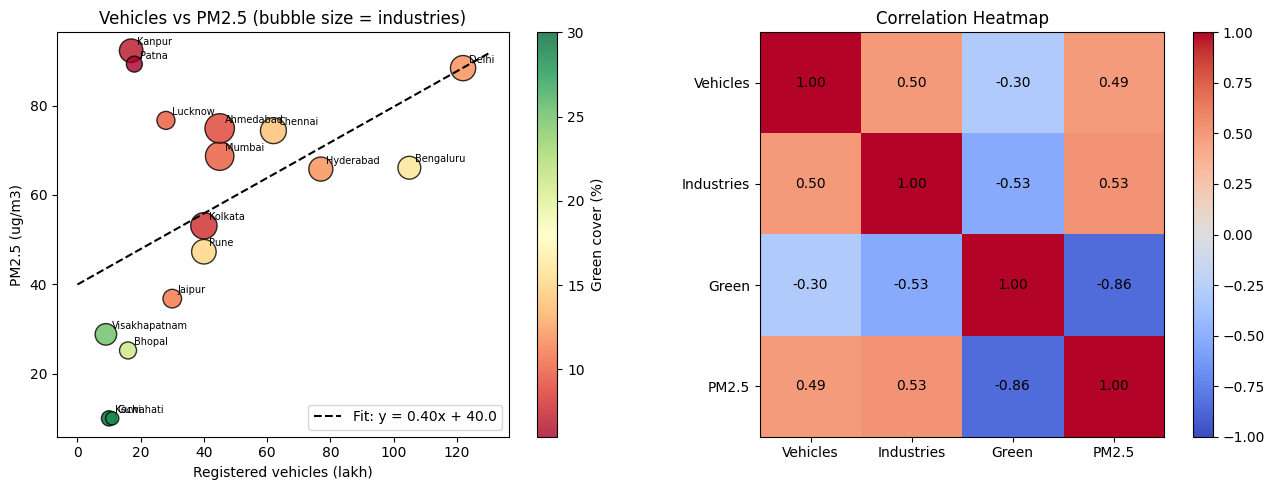

In [ ]:
#25/11/2026
#EXP 19
# Import required libraries
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ignore Basemap deprecation warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Import Basemap library
# If Basemap is unavailable, display an installation message
try:
    from mpl_toolkits.basemap import Basemap
except ImportError:
    Basemap = None
    print("Basemap not found. Install with: pip install basemap (or use Cartopy)")

# Define city details:
# City, latitude, longitude, vehicles, industries and green cover
records = [
    ("Delhi", 28.61, 77.21, 122, 55, 12),
    ("Mumbai", 19.08, 72.88, 45, 70, 10),
    ("Kolkata", 22.57, 88.36, 40, 60, 8),
    ("Chennai", 13.08, 80.27, 62, 58, 14),
    ("Bengaluru", 12.97, 77.59, 105, 45, 16),
    ("Hyderabad", 17.39, 78.49, 77, 50, 12),
    ("Ahmedabad", 23.02, 72.57, 45, 75, 9),
    ("Pune", 18.52, 73.86, 40, 52, 15),
    ("Jaipur", 26.91, 75.79, 30, 30, 11),
    ("Lucknow", 26.85, 80.95, 28, 28, 10),
    ("Kanpur", 26.45, 80.33, 17, 48, 7),
    ("Patna", 25.59, 85.14, 18, 22, 6),
    ("Bhopal", 23.26, 77.41, 16, 25, 21),
    ("Kochi", 9.93, 76.27, 10, 20, 30),
    ("Visakhapatnam", 17.69, 83.22, 9, 40, 25),
    ("Guwahati", 26.14, 91.74, 11, 15, 28)
]

# Define column names
cols = [
    "city", "lat", "lon",
    "vehicles_lakh", "industries", "green_cover"
]

# Convert records into a Pandas DataFrame
cities = pd.DataFrame(records, columns=cols)

# Set random seed
np.random.seed(2)

# Calculate PM2.5 pollution values
# Vehicles and industries increase pollution
# Green cover reduces pollution
cities["pm25"] = (
    25
    + 0.4 * cities["vehicles_lakh"]
    + 0.5 * cities["industries"]
    - 0.9 * cities["green_cover"]
    + np.random.normal(0, 5, len(cities))
).clip(lower=10).round(1)

# Identify cities in the Indo-Gangetic belt
belt = cities["city"].isin(["Kanpur", "Patna", "Lucknow"])

# Increase PM2.5 values for these cities
cities.loc[belt, "pm25"] += 40

# Display city-wise pollution data
print("Air Quality Analysis: Scatterplots, Correlation and Geographic Data")
print("=" * 68)

print(
    cities[
        ["city", "vehicles_lakh", "industries", "green_cover", "pm25"]
    ].to_string(index=False)
)

# ---------- Pearson Correlation Matrix ----------

# Calculate correlation between selected variables
corr = cities[
    ["vehicles_lakh", "industries", "green_cover", "pm25"]
].corr()

# Display correlation matrix
print("\nCorrelation matrix (Pearson):")
print(corr.round(3).to_string())

# Find the relationship between PM2.5 and other factors
for col in ["vehicles_lakh", "industries", "green_cover"]:

    # Extract correlation coefficient
    r = corr.loc[col, "pm25"]

    # Identify correlation strength
    strength = (
        "strong" if abs(r) > 0.6
        else "moderate" if abs(r) > 0.3
        else "weak"
    )

    # Print correlation interpretation
    print(
        f" pm25 vs {col:<13}: r = {r:+.3f} "
        f"({strength} {'positive' if r > 0 else 'negative'})"
    )

# Display three most and least polluted cities
print("\nMost polluted:", cities.nlargest(3, "pm25")["city"].tolist())
print("Least polluted:", cities.nsmallest(3, "pm25")["city"].tolist())

# ---------- Advanced Scatter Plot and Correlation Heatmap ----------

# Create two side-by-side plots
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Create scatter plot
# X-axis represents vehicles
# Y-axis represents PM2.5
# Bubble size represents industries
# Bubble colour represents green cover
sc = ax[0].scatter(
    cities["vehicles_lakh"],
    cities["pm25"],
    s=cities["industries"] * 6,
    c=cities["green_cover"],
    cmap="RdYlGn",
    edgecolors="black",
    alpha=0.8
)

# Calculate best-fit linear regression line
m, b = np.polyfit(cities["vehicles_lakh"], cities["pm25"], 1)

# Generate X values for fitted line
xs = np.linspace(0, 130, 50)

# Draw fitted line
ax[0].plot(
    xs, m * xs + b,
    "k--",
    label=f"Fit: y = {m:.2f}x + {b:.1f}"
)

# Add city names beside scatter points
for _, r in cities.iterrows():
    ax[0].annotate(
        r["city"],
        (r["vehicles_lakh"], r["pm25"]),
        fontsize=7,
        xytext=(4, 4),
        textcoords="offset points"
    )

# Add colour bar
fig.colorbar(sc, ax=ax[0], label="Green cover (%)")

# Set scatter plot labels and title
ax[0].set_xlabel("Registered vehicles (lakh)")
ax[0].set_ylabel("PM2.5 (ug/m3)")
ax[0].set_title("Vehicles vs PM2.5 (bubble size = industries)")
ax[0].legend()

# ---------- Correlation Heatmap ----------

# Display correlation matrix as heatmap
im = ax[1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

# Define heatmap axis labels
labels = ["Vehicles", "Industries", "Green", "PM2.5"]

ax[1].set_xticks(range(4), labels)
ax[1].set_yticks(range(4), labels)

# Display correlation values inside each cell
for i in range(4):
    for j in range(4):
        ax[1].text(
            j, i, f"{corr.iloc[i, j]:.2f}",
            ha="center", va="center"
        )

# Add colour bar and title
fig.colorbar(im, ax=ax[1])
ax[1].set_title("Correlation Heatmap")

# Adjust layout and save scatter plot
plt.tight_layout()
plt.savefig("exp19_scatter.png", dpi=150)

# ---------- Geographic Plot using Basemap ----------

# Check whether Basemap is installed
if Basemap is not None:

    # Create map figure
    plt.figure(figsize=(8, 8))

    # Define map projection and geographical boundaries
    mp = Basemap(
        projection="merc",
        llcrnrlat=6,
        urcrnrlat=36,
        llcrnrlon=67,
        urcrnrlon=98,
        resolution="l"
    )

    # Draw coastlines and country borders
    mp.drawcoastlines(linewidth=0.6)
    mp.drawcountries(linewidth=0.8)

    # Fill land and water regions
    mp.fillcontinents(color="#f2efe6", lake_color="#cfe8f7")
    mp.drawmapboundary(fill_color="#cfe8f7")

    # Draw latitude lines
    mp.drawparallels(
        range(5, 40, 5),
        labels=[1, 0, 0, 0],
        fontsize=8
    )

    # Draw longitude lines
    mp.drawmeridians(
        range(65, 100, 5),
        labels=[0, 0, 0, 1],
        fontsize=8
    )

    # Convert longitude and latitude into map coordinates
    x, y = mp(
        cities["lon"].values,
        cities["lat"].values
    )

    # Plot city locations
    # Size and colour represent PM2.5 levels
    pts = mp.scatter(
        x, y,
        s=cities["pm25"] * 4,
        c=cities["pm25"],
        cmap="YlOrRd",
        edgecolors="black",
        zorder=5
    )

    # Add city names on the map
    for xi, yi, name in zip(x, y, cities["city"]):
        plt.text(
            xi + 30000,
            yi + 30000,
            name,
            fontsize=8,
            zorder=6
        )

    # Add colour bar
    plt.colorbar(
        pts,
        shrink=0.6,
        label="PM2.5 (ug/m3)"
    )

    # Set map title
    plt.title("PM2.5 Levels across Indian Cities (Basemap)")

    # Save geographical map
    plt.savefig(
        "exp19_map.png",
        dpi=150,
        bbox_inches="tight"
    )

    print("\nSaved figures: exp19_scatter.png, exp19_map.png")

# Display all plots
plt.show()


Network Visualization: Undirected and Directed Graphs

Part A - Undirected collaboration network
Nodes: 9 | Edges: 12
Density: 0.333 | Connected: True
Researcher Degree  Betweenness
Fiona           4        0.589
Charu           4        0.429
Gautam          3        0.429
Deva            3        0.054
Asha            2        0.000
Bharath         2        0.000
Eswar           2        0.000
Hema            2        0.000
Irfan           2        0.000
Shortest path Asha -> Irfan: Asha - Charu - Fiona - Gautam - Irfan
Communities: [['Asha', 'Bharath', 'Charu'], ['Deva', 'Eswar', 'Fiona'], ['Gautam', 'Hema', 'Irfan']]

Part B - Directed flight network
Airports: 7 | Routes: 12
Airport     In  Out  PageRank
Delhi        3    2     0.202
Chennai      2    3     0.183
Kolkata      2    2     0.183
Bengaluru    2    2     0.146
Guwahati     1    0     0.113
Mumbai       1    2     0.087
Hyderabad    1    1     0.087
Shortest route Hyderabad -> Guwahati: Hyderabad -> Bengaluru -> Kolkata 

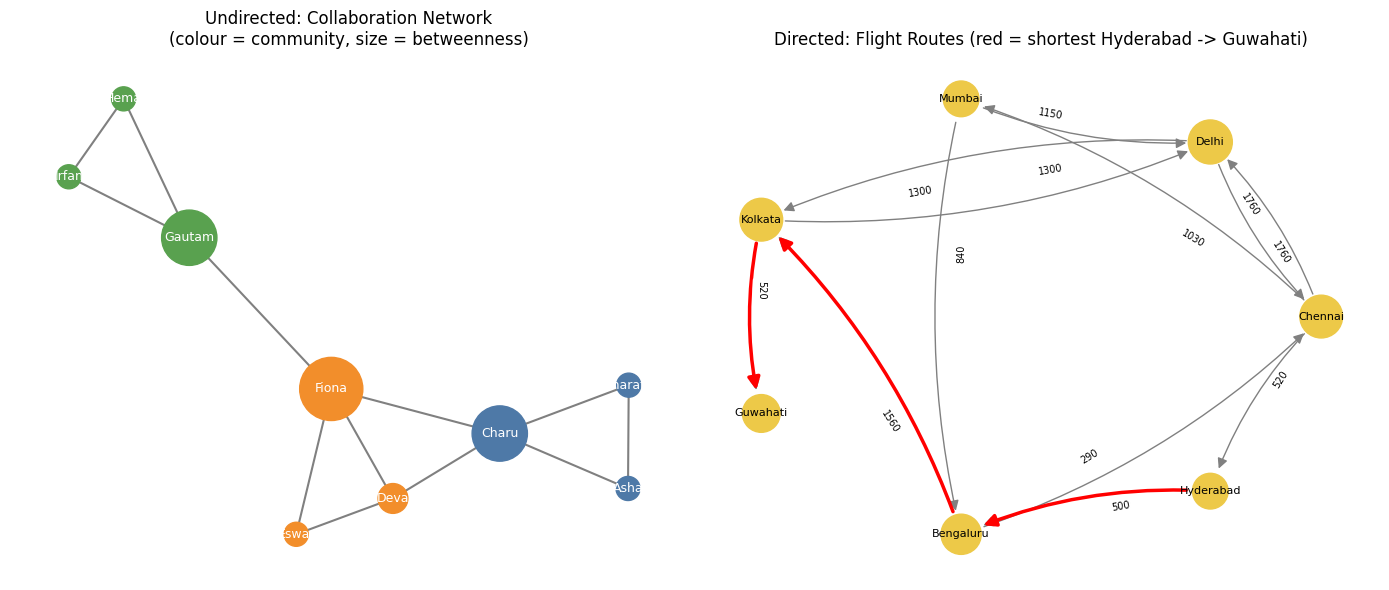


Saved figure: exp20_graphs.png


In [ ]:
#25/11/2026
#EXP 20
# Import required libraries
import networkx as nx
import matplotlib.pyplot as plt

# Display program heading
print("Network Visualization: Undirected and Directed Graphs")
print("=" * 54)

# ---------- Part A: Undirected Graph - Research Collaboration Network ----------

# Create an undirected graph
G = nx.Graph()

# Define collaboration connections between researchers
collaborations = [
    ("Asha", "Bharath"),
    ("Asha", "Charu"),
    ("Bharath", "Charu"),
    ("Charu", "Deva"),
    ("Deva", "Eswar"),
    ("Deva", "Fiona"),
    ("Eswar", "Fiona"),
    ("Fiona", "Gautam"),
    ("Gautam", "Hema"),
    ("Hema", "Irfan"),
    ("Gautam", "Irfan"),
    ("Charu", "Fiona")
]

# Add edges to the undirected graph
G.add_edges_from(collaborations)

# Display graph information
print("\nPart A - Undirected collaboration network")

# Display total number of nodes and edges
print("Nodes:", G.number_of_nodes(), "| Edges:", G.number_of_edges())

# Calculate graph density and check connectivity
print(
    "Density:", round(nx.density(G), 3),
    "| Connected:", nx.is_connected(G)
)

# Calculate degree of each researcher
deg = dict(G.degree())

# Calculate betweenness centrality
btw = nx.betweenness_centrality(G)

# Display researcher statistics
print(f"{'Researcher':<10}{'Degree':>7}{'Betweenness':>13}")

# Sort researchers by betweenness centrality
for n in sorted(G, key=lambda n: -btw[n]):
    print(f"{n:<10}{deg[n]:>7}{btw[n]:>13.3f}")

# Find shortest path from Asha to Irfan
print(
    "Shortest path Asha -> Irfan:",
    " - ".join(nx.shortest_path(G, "Asha", "Irfan"))
)

# Detect communities using greedy modularity method
communities = nx.algorithms.community.greedy_modularity_communities(G)

# Display detected communities
print("Communities:", [sorted(c) for c in communities])

# ---------- Part B: Directed Weighted Graph - Flight Routes ----------

# Create a directed graph
D = nx.DiGraph()

# Define flight routes and distances in kilometres
routes = [
    ("Chennai", "Delhi", 1760),
    ("Delhi", "Chennai", 1760),
    ("Chennai", "Mumbai", 1030),
    ("Mumbai", "Delhi", 1150),
    ("Delhi", "Kolkata", 1300),
    ("Kolkata", "Guwahati", 520),
    ("Mumbai", "Bengaluru", 840),
    ("Bengaluru", "Chennai", 290),
    ("Bengaluru", "Kolkata", 1560),
    ("Hyderabad", "Bengaluru", 500),
    ("Chennai", "Hyderabad", 520),
    ("Kolkata", "Delhi", 1300)
]

# Add weighted edges to the directed graph
D.add_weighted_edges_from(routes, weight="km")

# Display directed graph information
print("\nPart B - Directed flight network")

# Display number of airports and routes
print("Airports:", D.number_of_nodes(), "| Routes:", D.number_of_edges())

# Calculate PageRank for each airport
pr = nx.pagerank(D)

# Display airport statistics
print(f"{'Airport':<10}{'In':>4}{'Out':>5}{'PageRank':>10}")

# Sort airports according to PageRank
for n in sorted(D, key=lambda n: -pr[n]):

    # Display in-degree, out-degree and PageRank
    print(
        f"{n:<10}{D.in_degree(n):>4}"
        f"{D.out_degree(n):>5}{pr[n]:>10.3f}"
    )

# Find shortest route using Dijkstra's algorithm
path = nx.dijkstra_path(
    D, "Hyderabad", "Guwahati", weight="km"
)

# Calculate total distance of shortest route
dist = nx.dijkstra_path_length(
    D, "Hyderabad", "Guwahati", weight="km"
)

# Display shortest route and distance
print(
    "Shortest route Hyderabad -> Guwahati:",
    " -> ".join(path),
    f"({dist} km)"
)

# Check whether Guwahati has outgoing connections
print(
    "Can Guwahati reach any city?",
    D.out_degree("Guwahati") > 0
)

# Check whether the directed graph is strongly connected
print("Strongly connected:", nx.is_strongly_connected(D))

# ---------- Drawing Both Graphs ----------

# Create two side-by-side graph plots
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# ---------- Draw Undirected Graph ----------

# Calculate node positions using spring layout
pos = nx.spring_layout(G, seed=4)

# Define colours for different communities
colors = ["#4e79a7", "#f28e2b", "#59a14f", "#e15759"]

# Assign colours according to community membership
node_color = [
    colors[i]
    for n in G
    for i, c in enumerate(communities)
    if n in c
]

# Draw collaboration network
# Node size represents betweenness centrality
nx.draw_networkx(
    G,
    pos,
    ax=ax[0],
    node_color=node_color,
    node_size=[300 + 3000 * btw[n] for n in G],
    font_size=9,
    font_color="white",
    edge_color="gray",
    width=1.5
)

# Set title for undirected graph
ax[0].set_title(
    "Undirected: Collaboration Network\n"
    "(colour = community, size = betweenness)"
)

# Hide axis
ax[0].axis("off")

# ---------- Draw Directed Graph ----------

# Arrange airport nodes in circular layout
pos2 = nx.circular_layout(D)

# Draw airport nodes
# Node size represents PageRank
nx.draw_networkx_nodes(
    D,
    pos2,
    ax=ax[1],
    node_color="#edc948",
    node_size=[3000 * pr[n] + 400 for n in D]
)

# Display airport names
nx.draw_networkx_labels(
    D,
    pos2,
    ax=ax[1],
    font_size=8
)

# Draw directed flight connections with arrows
nx.draw_networkx_edges(
    D,
    pos2,
    ax=ax[1],
    arrowstyle="-|>",
    arrowsize=15,
    connectionstyle="arc3,rad=0.12",
    edge_color="gray",
    node_size=1200
)

# Extract edges belonging to the shortest route
path_edges = list(zip(path, path[1:]))

# Highlight shortest route using red arrows
nx.draw_networkx_edges(
    D,
    pos2,
    ax=ax[1],
    edgelist=path_edges,
    edge_color="red",
    width=2.5,
    arrowstyle="-|>",
    arrowsize=18,
    connectionstyle="arc3,rad=0.12",
    node_size=1200
)

# Display distance labels on flight connections
nx.draw_networkx_edge_labels(
    D,
    pos2,
    ax=ax[1],
    font_size=7,
    label_pos=0.35,
    edge_labels=nx.get_edge_attributes(D, "km")
)

# Set title for directed graph
ax[1].set_title(
    "Directed: Flight Routes "
    "(red = shortest Hyderabad -> Guwahati)"
)

# Hide axis
ax[1].axis("off")

# Adjust layout and save graph image
plt.tight_layout()
plt.savefig("exp20_graphs.png", dpi=150)

# Display both graphs
plt.show()

# Display saved figure name
print("\nSaved figure: exp20_graphs.png")
